In [8]:
import nptdms
import os
import pandas as pd
import numpy as np
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter



# 加载文件
def load_tdms_files(folder_path):
    """加载指定文件夹中的所有 TDMS 文件，并提取多通道数据"""
    tdms_data = pd.DataFrame()
    
    if not os.path.isdir(folder_path):
        raise ValueError(f"指定的路径 {folder_path} 不是一个有效的文件夹")
    
    for file_name in os.listdir(folder_path):
        if file_name.endswith(".tdms"):
            file_path = os.path.join(folder_path, file_name)
            try:
                tdms_file = nptdms.TdmsFile.read(file_path)
                channels_data = {}
                for group in tdms_file.groups():
                    for channel in group.channels():
                        channels_data[channel.name] = channel[:] 
                df_1 = pd.DataFrame(channels_data)
                tdms_data = pd.concat([tdms_data, df_1], ignore_index=True)
                print(f"成功加载 {file_name}，包含 {len(channels_data)} 个通道")
            except Exception as e:
                print(f"加载 {file_name} 失败: {e}")
    
    return tdms_data

#寻找峰的位置的函数
def find_peaks_position(data):
    numpy_smooth_data = gaussian_filter1d(df['Log(G/G0)'], SIGMA, axis=0)
    peaks, _ = find_peaks(numpy_smooth_data, height = 0.5, prominence=0.1) # 找出峰值位置
    print(len(peaks))
    return peaks # 返回峰值位置

# 拆分数据
def spilt_data(data, peaks):
    starts = [] # 起始位置
    ends = [] # 结束位置
    for i in range(len(peaks)-1):
        start = peaks[i]
#         end = df.Log(G/G0)[peaks[i]:peaks[i+1]].idxmin()
        end = peaks[i+1]
        starts.append(start) 
        ends.append(end)
    intervals = list(zip(starts, ends))
    return intervals

# 添加判断逻辑
def is_valid_ring(merged_df, overlap_threshold, separation_threshold, min_ring_width):
    # 计算红蓝线的绝对差值
    # 返回是蓝色在上面还是红色在上面
    merged_df['LogDiff'] = (merged_df['Log(G/G0)_red'] - merged_df['Log(G/G0)_blue'])
    # 计算红色在上面的比例 & 蓝色在上面的比例
    red_above = merged_df['LogDiff'] > 0
    blue_above = merged_df['LogDiff'] < 0
    max_ratio = max(red_above.mean(), blue_above.mean())
    if red_above.mean()>blue_above.mean():
        position = "red"
    else:
        position = "blue"
    if max_ratio < 0.6:  # 允许 10% 数据偏离
        # print("1:")
        return False,position
    # 判断是否存在重叠区域
    merged_df['LogDiff'] = merged_df['LogDiff'].abs()
    overlap_region = merged_df['LogDiff'] < overlap_threshold
    if overlap_region.sum() / len(merged_df) > 0.4:  # 如果 10% 的点是重叠的，认为有重叠
        #print(overlap_region.sum())
        # print("2:")
        return False,position

    # 判断是否存在分离的环
    separated_region = merged_df['LogDiff'] > separation_threshold
    separated_indices = np.where(separated_region)[0]
    # print(len(separated_indices))
    # 如果没有明显的分离区域，返回 False
    if len(separated_indices) < min_ring_width:
        # print("3:")
        return False,position

    # 检查是否形成一个完整的环（差值先减小再增大）
    diff_trend = np.diff(merged_df['LogDiff'])
    has_ring = (diff_trend[:len(diff_trend)//2] > 0).any() and (diff_trend[len(diff_trend)//2:] < 0).any()
    return has_ring,position


# ===== 新增：与直接 NPZ 版本相同的 SNR 判断；不影响原处理数据 =====
SNR_MIN = 5
SNR_MEDIAN_WINDOW = 31
SNR_MIN_ABS_BIAS = 0.10


def robust_noise_sigma(residual):
    """Scaled median absolute deviation (MAD), in Log(G/G0) units."""
    residual = np.asarray(residual, dtype=float)
    if not residual.size:
        return np.nan
    center = np.median(residual)
    return float(1.4826 * np.median(np.abs(residual - center)))


def compute_loop_snr(vf, gf, vr, gr,
                     window=SNR_MEDIAN_WINDOW,
                     min_abs_bias=SNR_MIN_ABS_BIAS):
    """Added criterion only. No smoothed data are passed to is_valid_ring().

    D: median |smooth_forward(V) - smooth_reverse(V)| on a common 2 mV grid.
    sigma: 1.4826 * MAD(raw - smoothed) for each scan, omitting |V| < 0.1 V.
    SNR = D / hypot(sigma_forward, sigma_reverse).
    """
    if window < 3 or window % 2 == 0:
        raise ValueError('SNR_MEDIAN_WINDOW must be odd and at least 3')

    smooth_f = median_filter(gf, size=window, mode='nearest')
    smooth_r = median_filter(gr, size=window, mode='nearest')

    mask_f = (np.abs(vf) >= min_abs_bias) & (np.abs(vf) <= 1.0)
    mask_r = (np.abs(vr) >= min_abs_bias) & (np.abs(vr) <= 1.0)
    sig_f = robust_noise_sigma((gf - smooth_f)[mask_f])
    sig_r = robust_noise_sigma((gr - smooth_r)[mask_r])

    # Match the two median-smoothed traces at the same Bias.
    # Unlike the original ring filter, this calculation uses a one-to-one grid:
    # it avoids counting repeated voltage samples multiple times in SNR.
    red = pd.DataFrame({'Bias': vf, 'smoothed': smooth_f}).groupby('Bias', sort=True)['smoothed'].median()
    blue = pd.DataFrame({'Bias': vr, 'smoothed': smooth_r}).groupby('Bias', sort=True)['smoothed'].median()
    common_min = max(float(red.index.min()), float(blue.index.min()))
    common_max = min(float(red.index.max()), float(blue.index.max()))
    grid = np.r_[np.linspace(-1.0, -0.1, 451), np.linspace(0.1, 1.0, 451)]
    grid = grid[(grid >= common_min) & (grid <= common_max)
                & (np.abs(grid) >= min_abs_bias)]
    if not grid.size or not np.isfinite(sig_f) or not np.isfinite(sig_r):
        return np.nan, np.nan, sig_f, sig_r

    f_on_grid = np.interp(grid, red.index.to_numpy(), red.to_numpy())
    r_on_grid = np.interp(grid, blue.index.to_numpy(), blue.to_numpy())
    D = float(np.median(np.abs(f_on_grid - r_on_grid)))
    denom = float(np.hypot(sig_f, sig_r))
    loop_snr = (D / denom if denom > 1e-12 else (np.inf if D > 0 else 0.0))
    return loop_snr, D, sig_f, sig_r


# ===== 新增 SNR 函数结束 =====

#创建一个文件夹
def get_unique_folder(base_folder):
    """
    如果文件夹已存在，则自动递增后缀数字，直到找到一个不存在的文件夹名。
    :param base_folder: 基础文件夹名
    :return: 不存在的文件夹路径
    """
    folder = base_folder
    count = 1
    while os.path.exists(folder):  # 如果文件夹已存在
        folder = f"{base_folder}_{count}"  # 添加后缀数字
        count += 1
    return folder

# 绘制筛选数据模块
def drawdata(group_data, group_name, first_change_idx, zero_crossing_idx):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

    # 左侧：绘制直方图
    log_data = group_data['Log(G/G0)'].dropna()
    ax1.hist(log_data, bins=300, density=True, alpha=0.5, label='Histogram')
    ax1.set_xlabel('Log(G/G0)')
    ax1.set_ylabel('Density')
    ax1.legend()
    ax1.set_title(f'Group {group_name}')

    # 右侧：绘制原始单条曲线，包含两个Y轴
    ax3 = ax2.twinx()
    ax2.set_xlabel('Index')
    ax2.set_ylabel('Log(G/G0)', color='tab:blue')
    ax2.plot(group_data.index, group_data['Log(G/G0)'], color='tab:blue', label='Log(G/G0)')
    ax2.tick_params(axis='y', labelcolor='tab:blue')
    ax2.set_ylim(-6, 4)

    ax3.set_ylabel('Bias (V)', color='tab:green')
    ax3.plot(group_data.index, group_data['Bias (V)'], color='tab:green', label='Bias (V)')
    ax3.tick_params(axis='y', labelcolor='tab:green')
    ax3.set_ylim(-5, 3)

    # 在 Bias 变化点处绘制竖线
    if not pd.isna(first_change_idx) and first_change_idx in group_data.index:
        ax2.axvline(x=first_change_idx, color='r', linestyle='--', label='Bias Change Point')

    # 在 Log(G/G0) 接近 0 的点处绘制竖线
    if not pd.isna(zero_crossing_idx) and zero_crossing_idx in group_data.index:
        ax2.axvline(x=zero_crossing_idx, color='orange', linestyle='--', label='Log(G/G0) ~ 0')
        log_value_at_zero_crossing = group_data.loc[zero_crossing_idx, 'Log(G/G0)']
        ax2.axhline(y=log_value_at_zero_crossing, color='purple', linestyle='-', label='Log(G/G0) ~ 0')

    # 添加 group_name 标签
    ax2.text(0.05, 0.95, f'Group {group_name}', transform=ax2.transAxes, fontsize=14, verticalalignment='top')

    ax2.set_title(f'Group {group_name} Original Data')
    ax2.legend()

    fig.tight_layout()
    plt.show()

# 保存iv图模块
def plot_iv_curve(red_list, blue_list, group_name, save_dir):
    # 提取 X 和 Y 轴数据
    plt.figure(figsize=(10, 6))

    # 转换成 DataFrame，按 Bias (V) 排序
    red_df = pd.DataFrame(red_list, columns=['Bias (V)', 'Log(G/G0)', 'Current (mA)']).sort_values('Bias (V)')
    blue_df = pd.DataFrame(blue_list, columns=['Bias (V)', 'Log(G/G0)','Current (mA)']).sort_values('Bias (V)')

    # 计算相邻 Bias (V) 之间的变化，判断递增递减
    red_df['diff'] = red_df['Bias (V)'].diff()
    blue_df['diff'] = blue_df['Bias (V)'].diff()

    # 拆分不同的 segment（电压变化方向相反时，作为新的 segment 开始）
    red_segments = [red_df.iloc[indexes] for indexes in np.split(np.arange(len(red_df)), np.where(red_df['diff'] < 0)[0] + 1)]
    blue_segments = [blue_df.iloc[indexes] for indexes in np.split(np.arange(len(blue_df)), np.where(blue_df['diff'] < 0)[0] + 1)]
    
    # 画出每个 segment
    for segment in red_segments:
        plt.plot(segment['Bias (V)'], segment['Log(G/G0)'], color='red')
    for segment in blue_segments:
        plt.plot(segment['Bias (V)'], segment['Log(G/G0)'], color='blue')

    plt.xlabel("Bias (V)")
    plt.ylabel("Log(G/G0)")
    plt.title(f"Group {group_name}: Bias (V) vs Log(G/G0)")
    plt.grid(True, linestyle="--", linewidth=0.5)

    file_name = f"iv_{group_name}.png"
    file_path = os.path.join(save_dir, file_name)
    plt.savefig(file_path, dpi=300)
    plt.close()

folder_selected = r"Z:\Experimental_Data\STM-Spin\XHY\苏州大学合作_C82\20260811 CeF@C82 iv"
# folder_selected = "Z:\Data\gqx\data\mltest"
if folder_selected:
    print(f"用户选择的文件夹: {folder_selected}")
    df = load_tdms_files(folder_selected)
else:
    print("未选择文件夹")

# 找峰位置  ***********************************************************************************************************************************
SIGMA = 100 # 高斯滤波参数
peaks = find_peaks_position(df)
# print(peaks)

conduct_data = pd.DataFrame(columns=['Group','conduct'])
# 电导数据拆分
intervals = spilt_data(df, peaks)

# 给每个单条包含的数据赋值number 方便后面检索绘图
df['Number'] = 0
# 使用 .loc 进行赋值
for i, (start, end) in enumerate(intervals):
    df.loc[start:end-1, 'Number'] = i + 1

# 获取 'Bias (V)' 列的所有唯一值
unique_bias_values = df['Bias (V)'].unique()
unique_bias_values_round = unique_bias_values.round(6)

# 计算电导 ***********************************************************************************************************************************
selected_data_diff = pd.DataFrame()
df_filtered = df[df['Number'] != 0]
grouped = df_filtered.groupby('Number')
conduct_data_list = []  # 用于存储 conduct_data 的数据
selected_data_list = []  # 用于存储 selected_data_diff 的数据

for group_name, group_data in grouped:
    group_data['Rounded_Bias'] = group_data['Bias (V)'].round(6)
    if -1 in group_data['Rounded_Bias'].values and 1 in group_data['Rounded_Bias'].values:
        # 找到 Log(G/G0) < 0 的第一个索引
        zero_crossing_idx = group_data.index[group_data['Log(G/G0)'] < 0].min()
        if pd.isna(zero_crossing_idx):
            zero_crossing_idx = group_data.index[-1]  # 如果没有小于0的点，默认取最后一个点

        # 计算 Bias (V) 变化的点数
        initial_bias = group_data['Rounded_Bias'].iloc[0]
        first_change_idx = group_data.index[group_data['Rounded_Bias'] != initial_bias].min()

        if pd.isna(first_change_idx):
            first_change_idx = group_data.index[-1]  # 如果没有变化点，默认取最后一个点

        # 计算 Log(G/G0) 接近于 0 点到 Bias 变化点之间的点数
        point_count = first_change_idx - zero_crossing_idx + 1  # 加1 计算点数

        # 存储 conduct_data
        conduct_data_list.append({'Group': group_name, 'conduct': point_count})
        # 存储 selected_data_diff
        selected_data_list.append(group_data)
        # if group_name==37:
        #     drawdata(group_data, group_name, first_change_idx, zero_crossing_idx)
        #     print(first_change_idx,ze)

# 一次性转换为 DataFrame，避免多次 pd.concat 操作
conduct_data = pd.DataFrame(conduct_data_list)
selected_data_diff = pd.concat(selected_data_list, axis=0)
print('total_Number:', len(selected_data_diff['Number'].unique()))

# 切分Bias从0~1~0~-1~0的部分 ***********************************************************************************************************************************
filtered_groups = []

grouped = selected_data_diff.groupby('Number')

for group_name, group_data in grouped:
    # 找到切分的起点和终点
    start_indices = group_data.index[
        (group_data["Bias (V)"] == 0) &  # 当前 Bias (V) == 0
        (group_data["Bias (V)"].shift(1, fill_value=0) == 0) &  # 前一个 Bias (V) == 0
        (group_data["Bias (V)"].shift(-1, fill_value=0) != 0)   # 后一个 Bias (V) != 0
    ].tolist()

    end_indices = group_data.index[
        (group_data["Bias (V)"] == 0) &
        (group_data["Bias (V)"].shift(1, fill_value=0) != 0) &  # 前一个 Bias (V) != 0
        (group_data["Bias (V)"].shift(-1, fill_value=0) == 0)    # 后一个 Bias (V) == 0
    ].tolist()

    # 检查起点和终点数量是否匹配
    if len(start_indices) != len(end_indices):
        raise ValueError(f"分组 {group_name} 的切分起点和终点数量不匹配，请检查数据。")
    
    # 筛选最小的 start 和最大的 end
    if len(start_indices) >= 2 and len(end_indices) >= 2:
        start = min(start_indices[:2])  # 取索引较小的 start
        end = max(end_indices[:2])  # 取索引较大的 end
        valid_segments = [(start, end)]
    else:
        valid_segments = []

    # 遍历所有有效区间，并筛选数据
    for start, end in valid_segments:
        if start in group_data.index and end in group_data.index:
            # 仅保留 start:end+1 这一部分数据
            filtered_data = group_data.loc[start:end + 1].copy()

            # 计算电压变化并确定 Scan Direction
            voltage_diff = filtered_data["Bias (V)"].diff().fillna(0)
            filtered_data['Scan Direction'] = ['forward' if diff > 0 else 'reverse' for diff in voltage_diff]

            # 将处理好的数据存入列表
            filtered_groups.append(filtered_data)

        else:
            print(f"Skipping invalid segment for Group {group_name} - Start: {start}, End: {end}")

# 合并所有处理后的数据
filtered_df = pd.concat(filtered_groups, ignore_index=True)

# 悬停判定 ***********************************************************************************************************************************
valid_df=pd.DataFrame()
for group_name, group_data in filtered_df.groupby('Number'):
    # if group_name == 1215:
        bias_values = group_data['Bias (V)'].values
        log_values = group_data['Log(G/G0)'].values
        
        # 找到 Bias = 0 的所有索引
        zero_indices = np.where(bias_values == 0)[0]

        if len(zero_indices) < 2:
            continue  # 确保有至少两个 Bias = 0 的点，否则跳过

        first_zero_idx = zero_indices[0]  # 第一个 Bias = 0 的索引
        second_zero_idx = zero_indices[1]  # 第二个 Bias = 0 的索引

        # 计算 log_start：第一个 Bias=0 后100个点到第二个 Bias=0 前50个点
        start_idx = first_zero_idx + 100
        end_idx = max(second_zero_idx - 50, start_idx)  # 确保索引顺序正确
        log_start = log_values[start_idx:end_idx].mean() if start_idx < end_idx else np.nan

        if -4 <= log_start <= -2.6:
            # 计算 log_end：第二个 Bias=0 后100个点 到 最后一个 Bias=1 前100个点
            start_idx_end = second_zero_idx + 100
            # 找到最后一个 Bias = 0 的索引
            last_one_idx = np.where(bias_values == 0)[0]
            if len(last_one_idx) > 0:
                last_one_idx = last_one_idx[-1]  # 取最后一个 Bias=0 的索引
            else:
                last_one_idx = len(bias_values)  # 如果没有 Bias=0，则取数据的最后一个索引

            end_idx_end = max(last_one_idx - 100, start_idx_end)  # 确保索引顺序正确
            log_end = log_values[start_idx_end:end_idx_end].mean() if start_idx_end < end_idx_end else np.nan
            if -4 <= log_end <=-2.6:
                # 计算 log_0：第二个 Bias=0 的前50个点和后50个点
                start_idx_0 = max(second_zero_idx - 10, 0)  # 确保索引不越界
                end_idx_0 = min(second_zero_idx + 10, len(log_values))  # 取 Bias=0 后一个点
                log_0 = log_values[start_idx_0:end_idx_0].mean()
                 # print(start_idx_0)
                if log_0 <-2.6:
                    valid_df = pd.concat([valid_df, group_data], axis=0)

        # if -5 <= log_start <= -3 and -5 <= log_end <=-3 and log_0 <-3:
        #     valid_df = pd.concat([valid_df, group_data], axis=0)
    # # 输出计算结果
        # drawdat(group_data, group_name)
        # print(f"Group: {group_name}, log_start: {log_start}, log_0: {log_0}, log_end: {log_end}, log_0_value:{log_0_value}")


# 寻找有效数据***************************************************************************************************************************
base_folder = r"D:\data\苏州大学合作C82\Ce_IV_new"

# 获取唯一的文件夹路径并创建
save_dir = get_unique_folder(base_folder)
os.makedirs(save_dir)
print(f"图片将保存到：{os.path.abspath(save_dir)}")

# 保存结果
log_diff_count = 0
sum_count = 0
valid_count = 0

final_data = pd.DataFrame(columns=['Group', 'Bias (V)', 'Log(G/G0)', 'Current (mA)','color'])
final_conduct_data = pd.DataFrame(columns=['Group', 'conduct'])

overlap_threshold = 0.1  # 红蓝线重叠的差值小于此值时认为是重叠
separation_threshold = 0.3  # 红蓝线差值大于此值时认为是分离
min_ring_width = 400  # 环的最小宽度（数据点数量）

snr_records = []  # 仅记录通过原回滞筛选的曲线 SNR

for group_name, group_data in valid_df.groupby('Number'):
        #保存数据后面后进行图片存储

        red_data = []
        blue_data = []
        #保存-1~-0.5之间的数据
        left_blue_data_fragment = []
        left_red_data_fragment= []
        right_blue_data_fragment = []
        right_red_data_fragment= []
        red_list = []
        blue_list = []
        log_diff_count = 0
        sum_count = sum_count+1
        red_list = group_data[group_data['Scan Direction'] == 'forward'][['Bias (V)', 'Log(G/G0)', 'Current (mA)']].values.tolist()
        blue_list = group_data[group_data['Scan Direction'] == 'reverse'][['Bias (V)', 'Log(G/G0)', 'Current (mA)']].values.tolist()
        # 直接从 DataFrame 筛选，不使用 list
        left_red_data_fragment = group_data[
            (group_data['Scan Direction'] == 'forward') &
            (group_data['Bias (V)'] >= -1) & (group_data['Bias (V)'] <= -0.1)
        ]

        left_blue_data_fragment = group_data[
            (group_data['Scan Direction'] == 'reverse') &
            (group_data['Bias (V)'] >= -1) & (group_data['Bias (V)'] <= -0.1)
        ]

        right_red_data_fragment = group_data[
            (group_data['Scan Direction'] == 'forward') &
            (group_data['Bias (V)'] >= 0.1) & (group_data['Bias (V)'] <= 1)
        ]

        right_blue_data_fragment = group_data[
            (group_data['Scan Direction'] == 'reverse') &
            (group_data['Bias (V)'] >= 0.1) & (group_data['Bias (V)'] <= 1)
        ]

        # 计算左边红色和蓝色数据点的差值
        left_red_df = pd.DataFrame(left_red_data_fragment, columns=['Bias (V)', 'Log(G/G0)'])
        left_blue_df = pd.DataFrame(left_blue_data_fragment, columns=['Bias (V)', 'Log(G/G0)'])
        # 合并红色和蓝色数据点
        left_merged_df = pd.merge(left_red_df, left_blue_df, on='Bias (V)', suffixes=('_red', '_blue')) 
        #print(left_merged_df.head())

        # 计算右边红色和蓝色数据点的差值
        right_red_df = pd.DataFrame(right_red_data_fragment, columns=['Bias (V)', 'Log(G/G0)'])
        right_blue_df = pd.DataFrame(right_blue_data_fragment, columns=['Bias (V)', 'Log(G/G0)'])
        # 合并红色和蓝色数据点
        right_merged_df = pd.merge(right_red_df, right_blue_df, on='Bias (V)', suffixes=('_red', '_blue')) 

        #判断是否有环以及左边方向，看是红色在上面还是蓝色在上面
        is_leftring,left_position = is_valid_ring(left_merged_df, overlap_threshold, separation_threshold, min_ring_width)
        #print(is_leftring)
        #print(is_leftring,left_position)
        #print(is_leftring,group_name)
        is_ring = True
        redli = np.array(red_list)
        blueli = np.array(blue_list)
        redmin = np.argmin(redli[:,1])
        argbiared = redli[redmin][0]
        bluemin = np.argmin(blueli[:,1])
        argbiablue = blueli[bluemin][0]
        if abs(argbiared-argbiablue) < 0.05:
            if is_leftring:
                is_rightring,right_position = is_valid_ring(right_merged_df, overlap_threshold, separation_threshold, min_ring_width)
                # print(is_rightring,right_position)
                # 如果右边有环，就要判断是否右边和左边的方向一致
                if is_rightring:
                    if right_position != left_position:
                        is_ring = False
                    if is_ring:
                        # if right_position == "red":
                            # 新增唯一的筛选条件：沿用直接 NPZ 版的全局 SNR >= 3
                            snr_value, D_logG, sigma_forward, sigma_reverse = compute_loop_snr(
                                redli[:, 0], redli[:, 1], blueli[:, 0], blueli[:, 1]
                            )
                            snr_records.append({
                                'Group': group_name,
                                'SNR_loop': snr_value,
                                'D_logG': D_logG,
                                'sigma_forward': sigma_forward,
                                'sigma_reverse': sigma_reverse,
                                'SNR_pass': bool(snr_value >= SNR_MIN)
                            })
                            if not (snr_value >= SNR_MIN):
                                continue  # 未通过SNR，不执行后面的原有保存步骤
                            valid_count = valid_count+1
                            # if valid_count < 50:
                            #     #save_iv(red_data,blue_data,group_name,save_dir)
                            plot_iv_curve(red_list,blue_list,group_name,save_dir)
                            red_list = pd.DataFrame(red_list,columns=['Bias (V)','Log(G/G0)','Current (mA)'])
                            red_list['Group'] = group_name
                            red_list['color'] = 'red'
                            #print(red_list)
                            blue_list = pd.DataFrame(blue_list,columns=['Bias (V)','Log(G/G0)','Current (mA)'])
                            blue_list['Group'] = group_name
                            blue_list['color'] = 'blue'
                            combined_df = pd.concat([red_list, blue_list], ignore_index=True)
                            final_data = pd.concat([final_data, combined_df], ignore_index=True)
                            # 保存电导
                            conduct_value = conduct_data.loc[conduct_data['Group'] == group_name, 'conduct'].values[-1]
                            final_conduct_data = pd.concat([final_conduct_data, pd.DataFrame({'Group': [group_name], 'conduct': [conduct_value]})], ignore_index=True)
                #print(group_name)
            # else:
            #     print(group_name)

print(f"总条数：{sum_count},有环条数：{valid_count}")
# CSV 文件路径
csv_file_path = os.path.join(save_dir, "valid_IV_data.csv")
# 保存 CSV
final_data.to_csv(csv_file_path, index=False)
# CSV 文件路径
excel_file_path = os.path.join(save_dir, "valid_Conduct_data.xlsx")
# 保存 CSVzxcv
final_conduct_data.to_excel(excel_file_path, index=False)

excel_file_path1 = os.path.join(save_dir, "total_Conduct_data.xlsx")
conduct_data.to_excel(excel_file_path1, index=False)

# ===== 新增：独立 SNR 统计文件（不改变原有输出） =====
snr_columns = ['Group', 'SNR_loop', 'D_logG', 'sigma_forward', 'sigma_reverse', 'SNR_pass']
pd.DataFrame(snr_records, columns=snr_columns).to_csv(
    os.path.join(save_dir, 'SNR_screening_metrics.csv'), index=False
)
print(f'原回滞条件通过: {len(snr_records)} 条；'
      f'新增 SNR >= {SNR_MIN:g} 后通过: {valid_count} 条；'
      f'SNR 排除: {len(snr_records) - valid_count} 条')


用户选择的文件夹: Z:\Experimental_Data\STM-Spin\XHY\苏州大学合作_C82\20260811 CeF@C82 iv
成功加载 0809CeF@C82 iv 1.0v - 00 - 00012.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 00024.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 00036.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 00048.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 000510.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 000612.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 000714.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 000816.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 000918.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 001020.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 001122.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 001224.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 001326.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 001428.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 001530.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 001632.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 00 - 001734.tdms，包含 3 个通道
成功加载 0809CeF@C82 iv 1.0v - 0

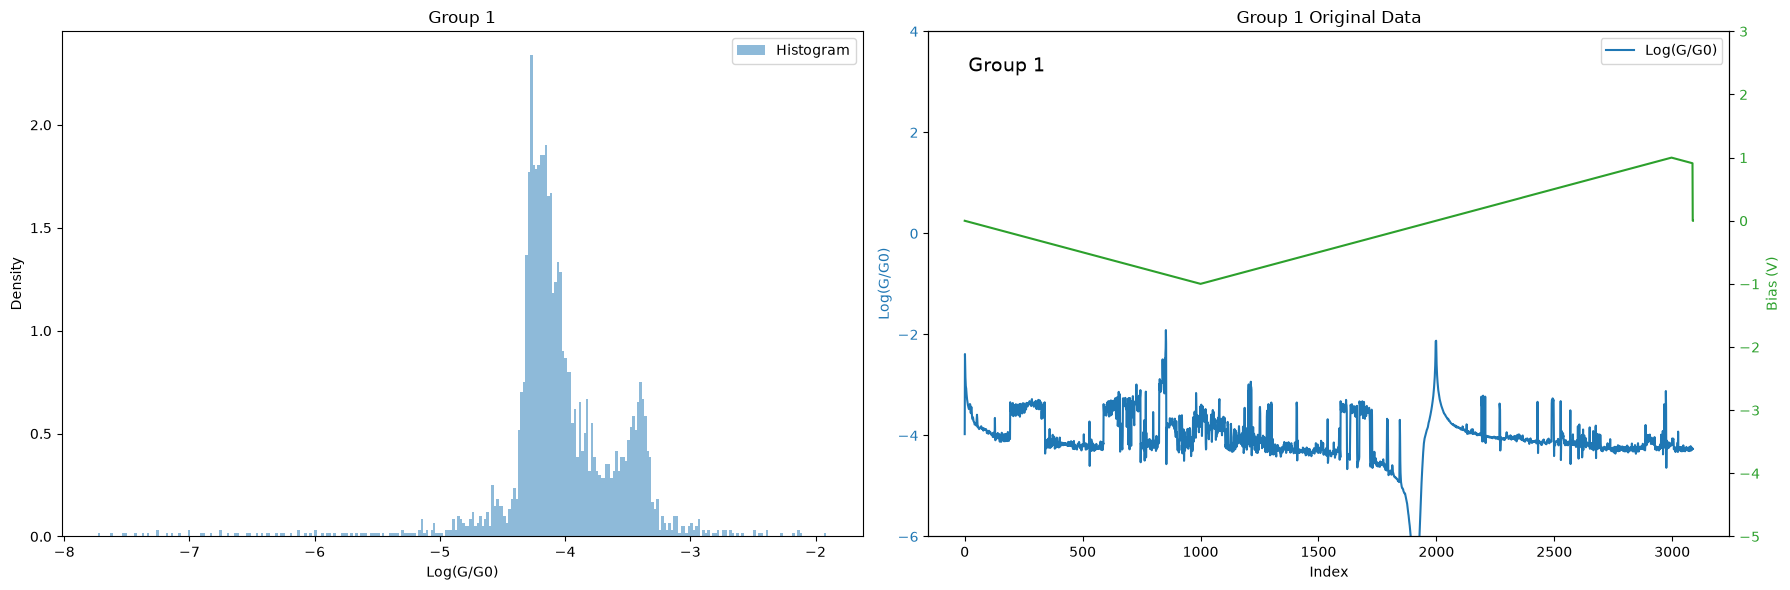

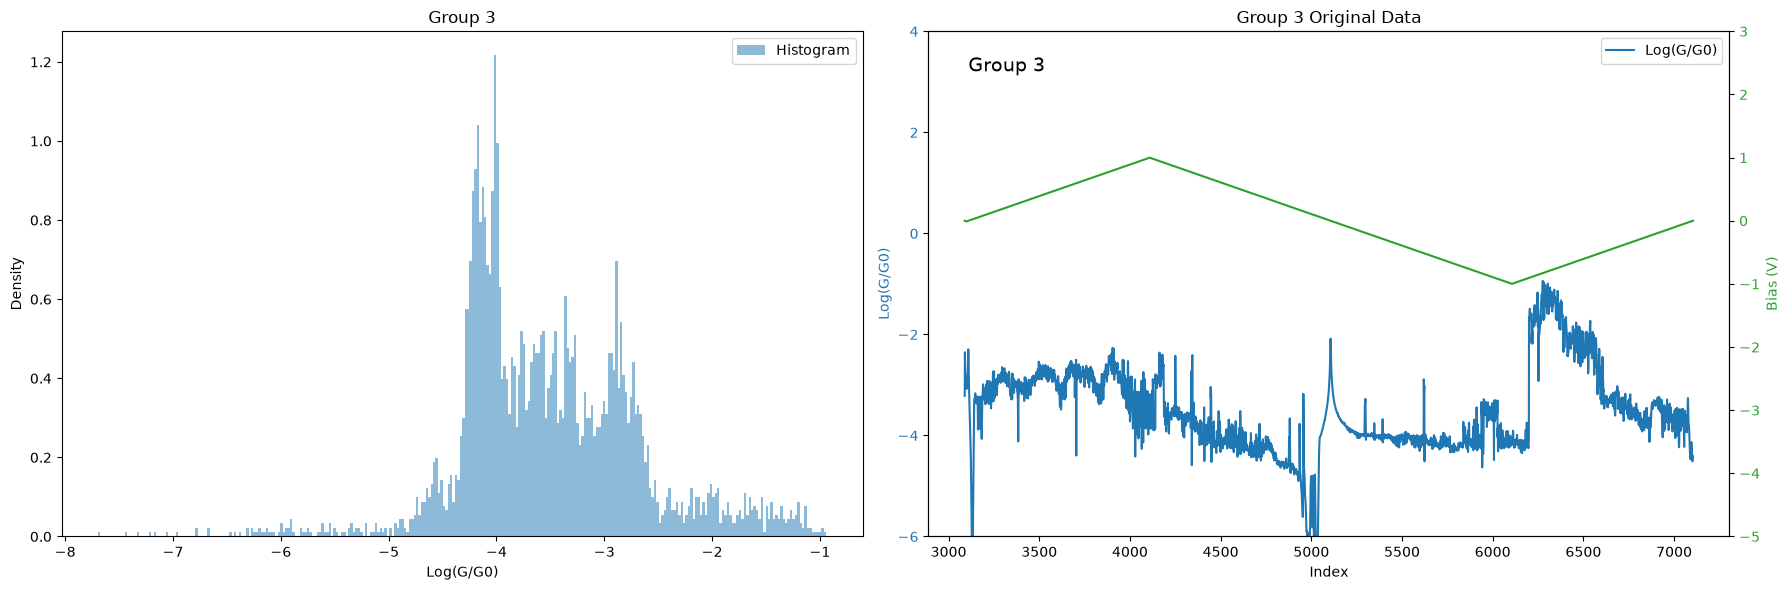

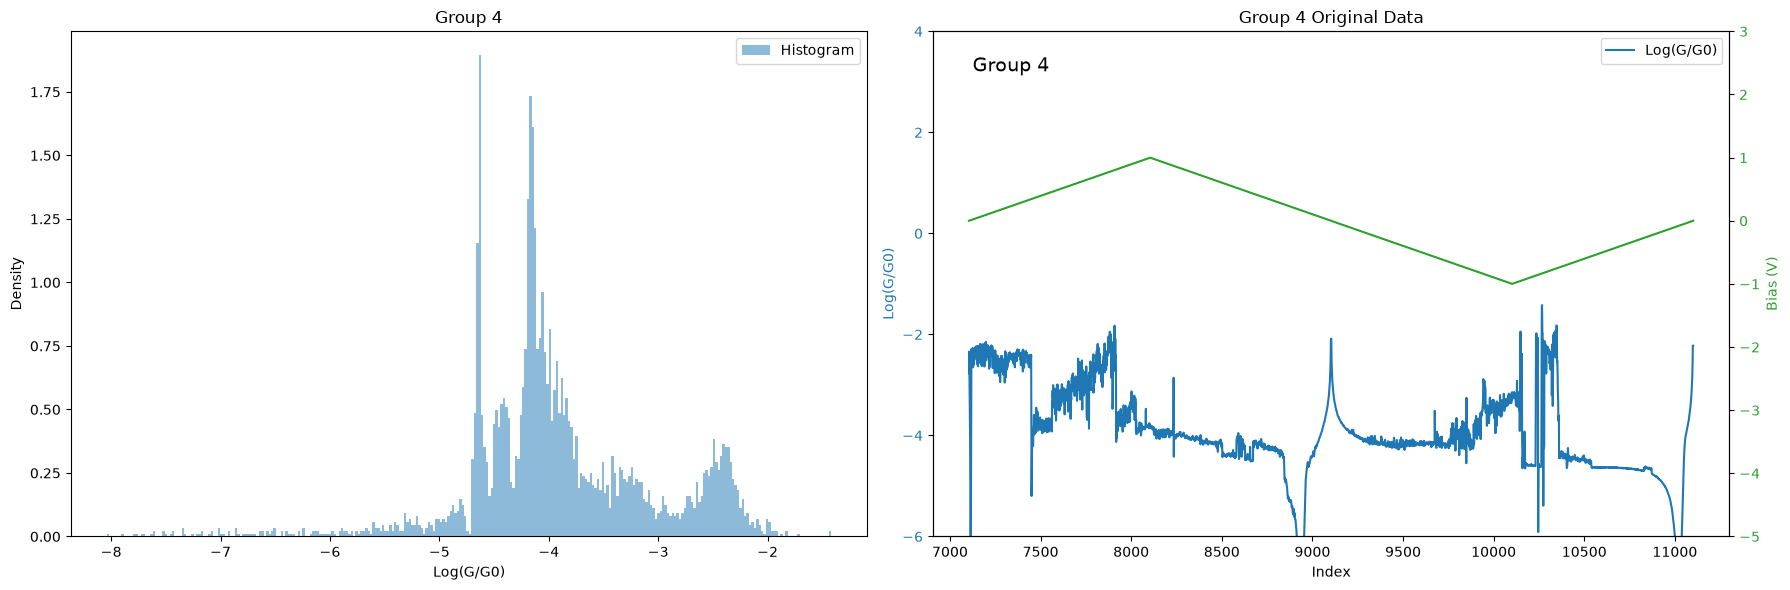

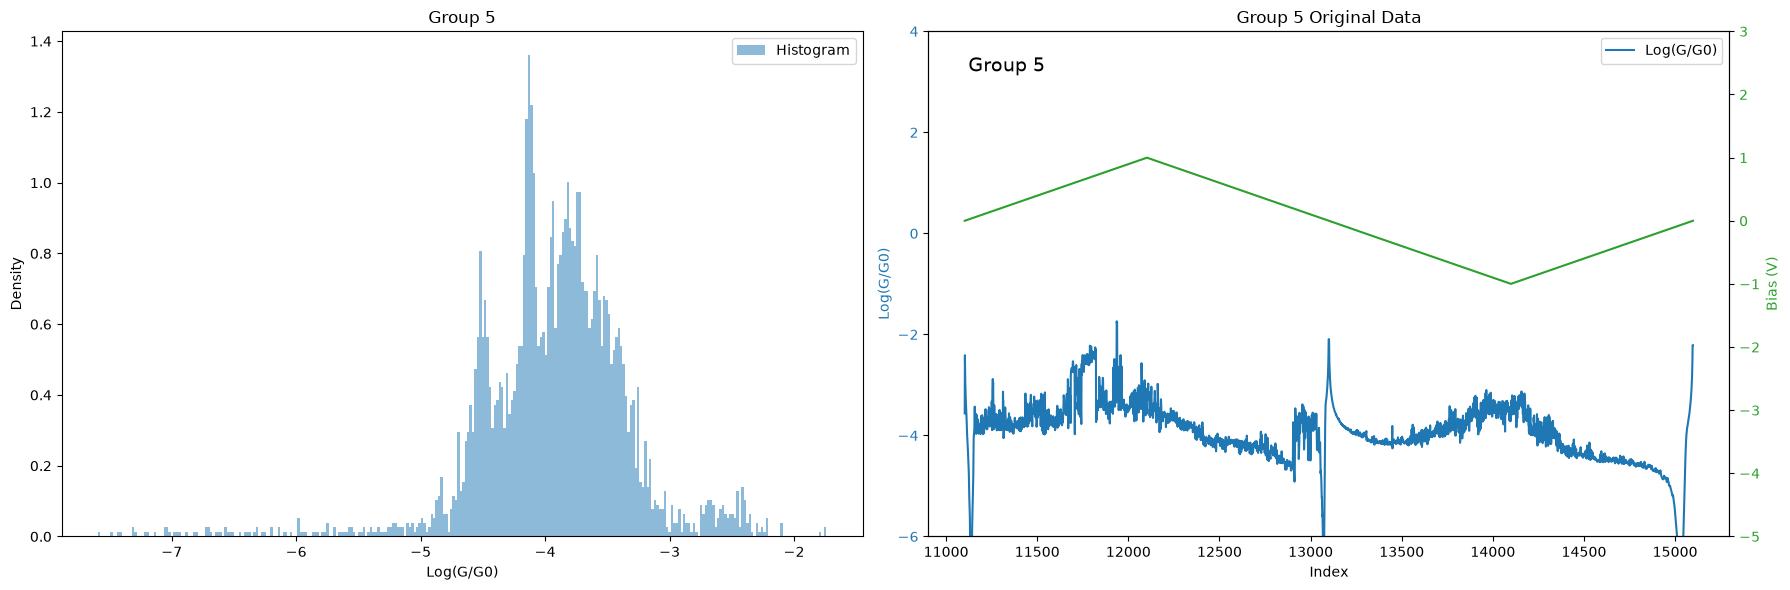

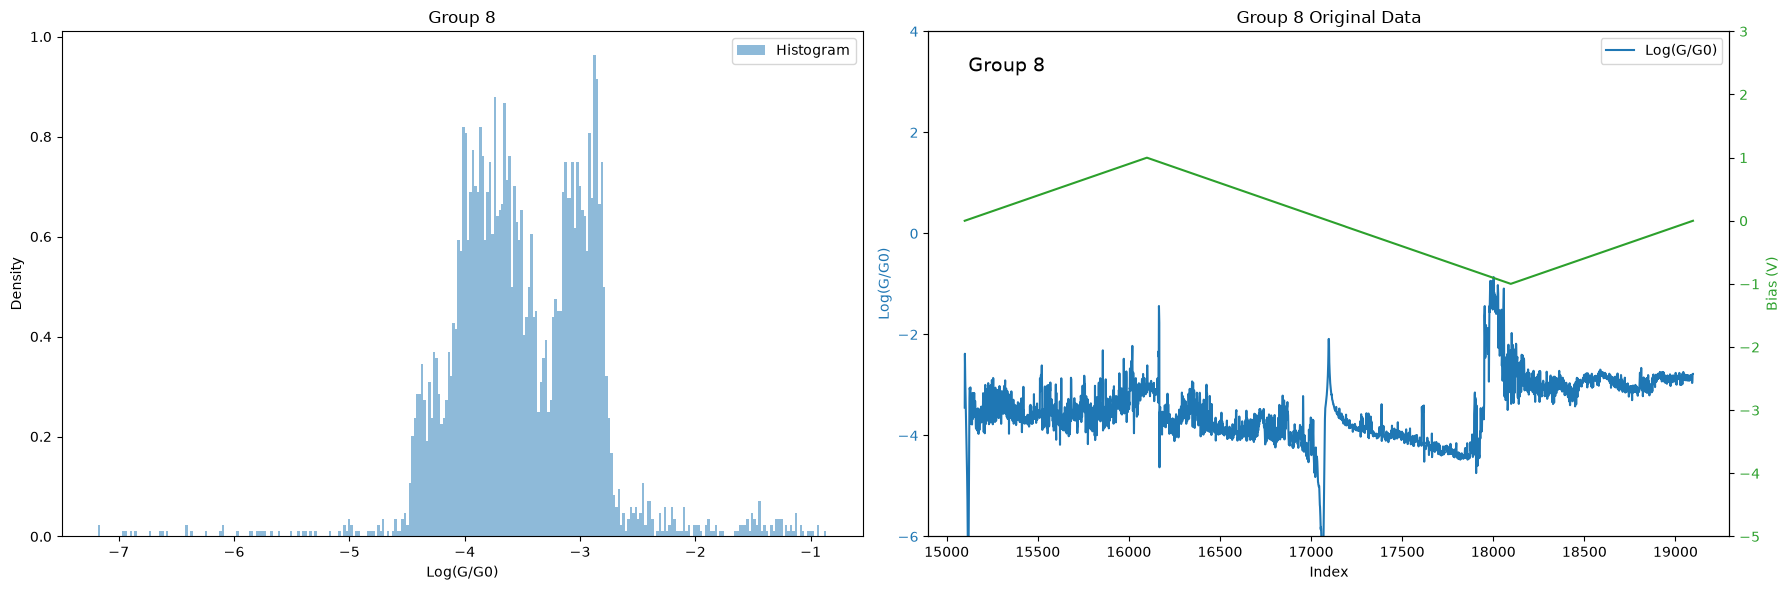

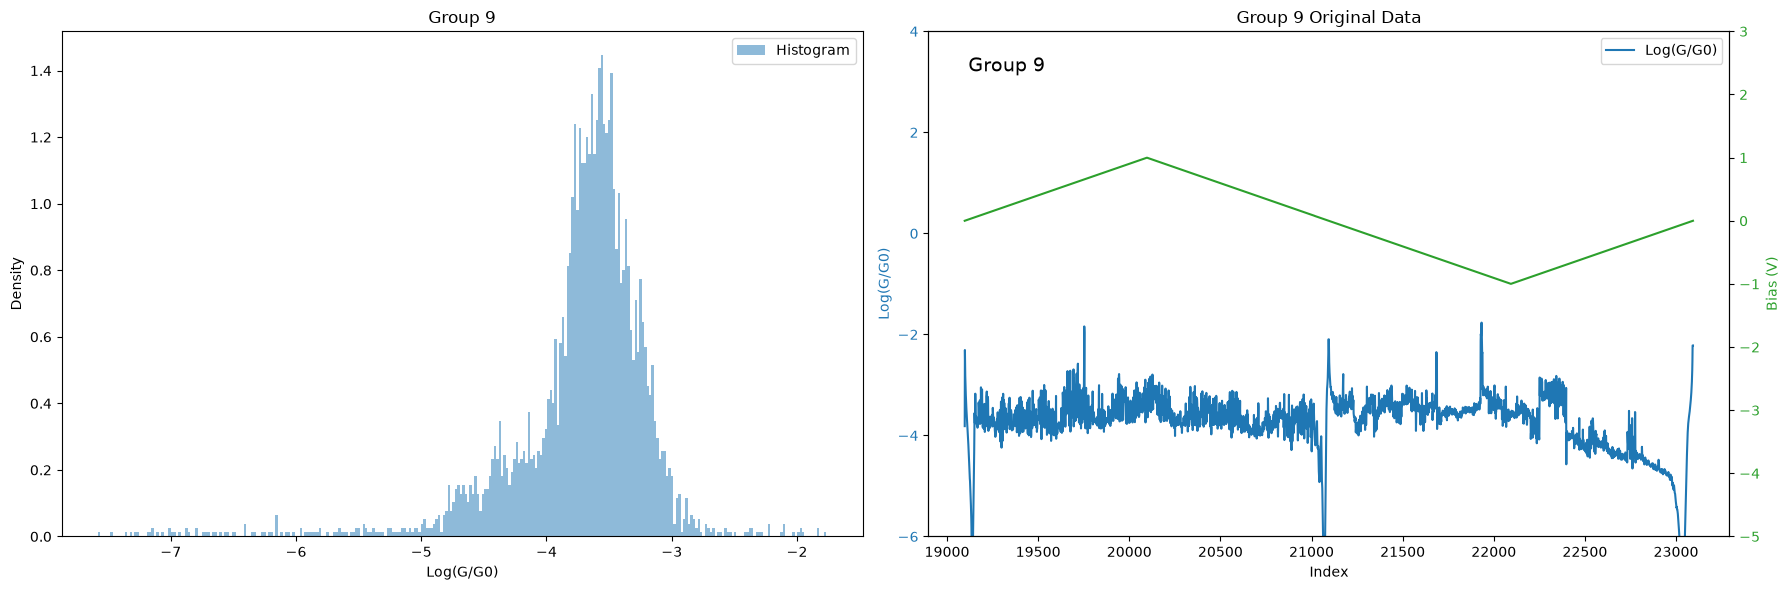

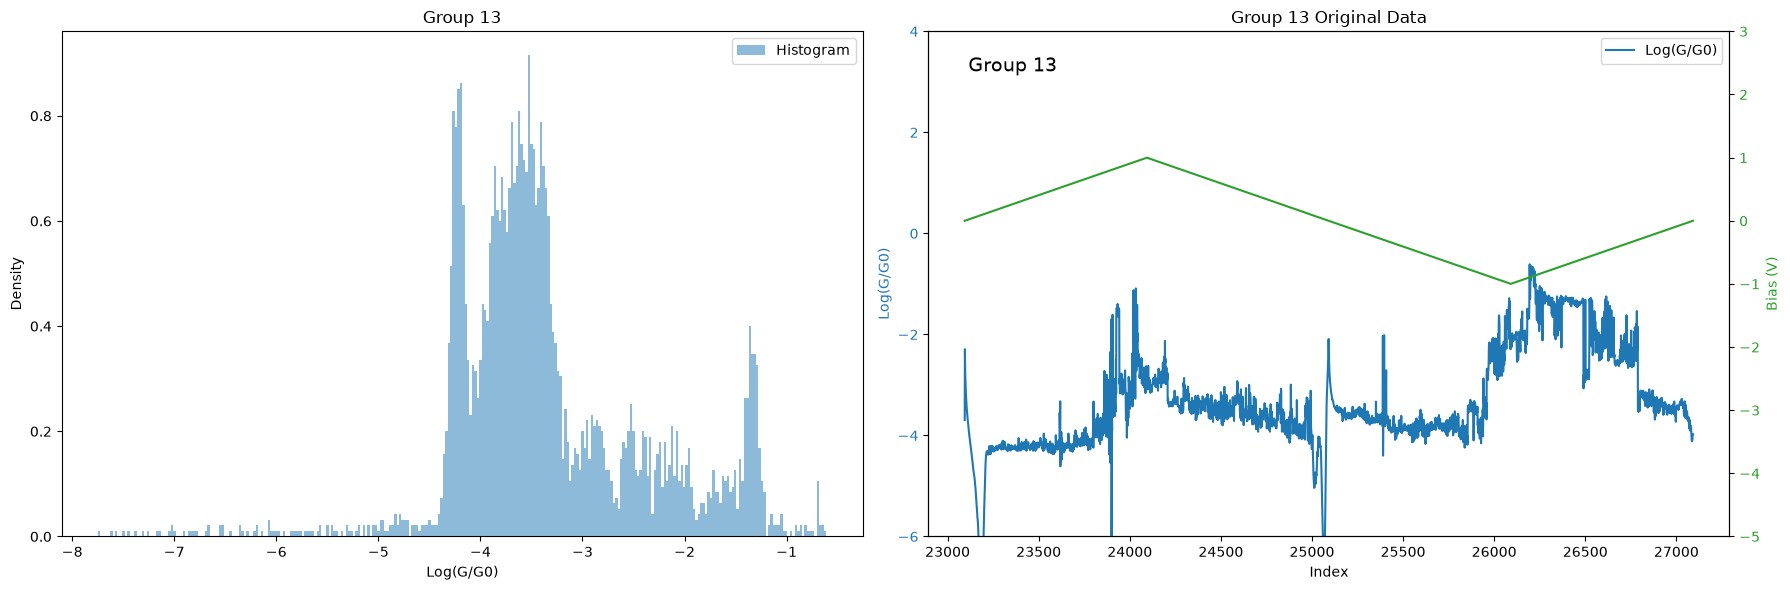

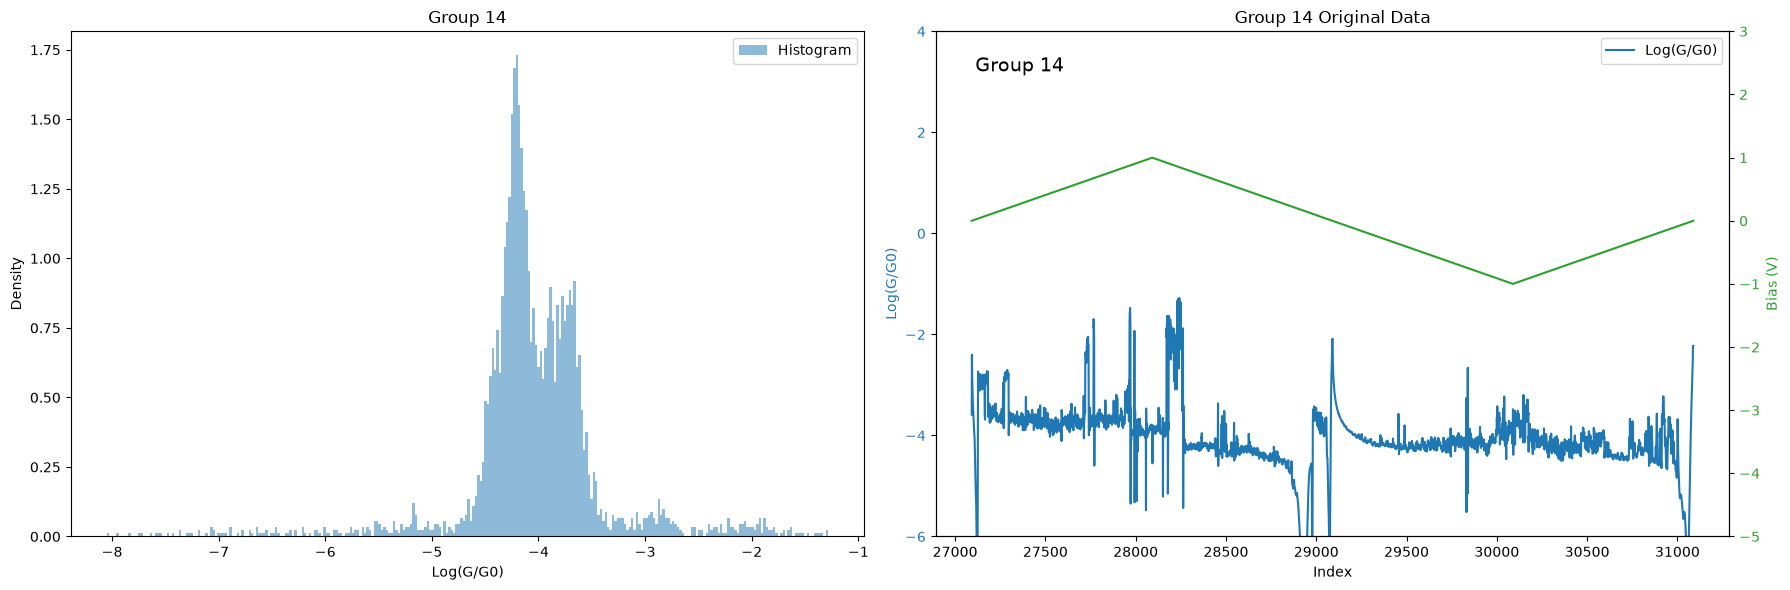

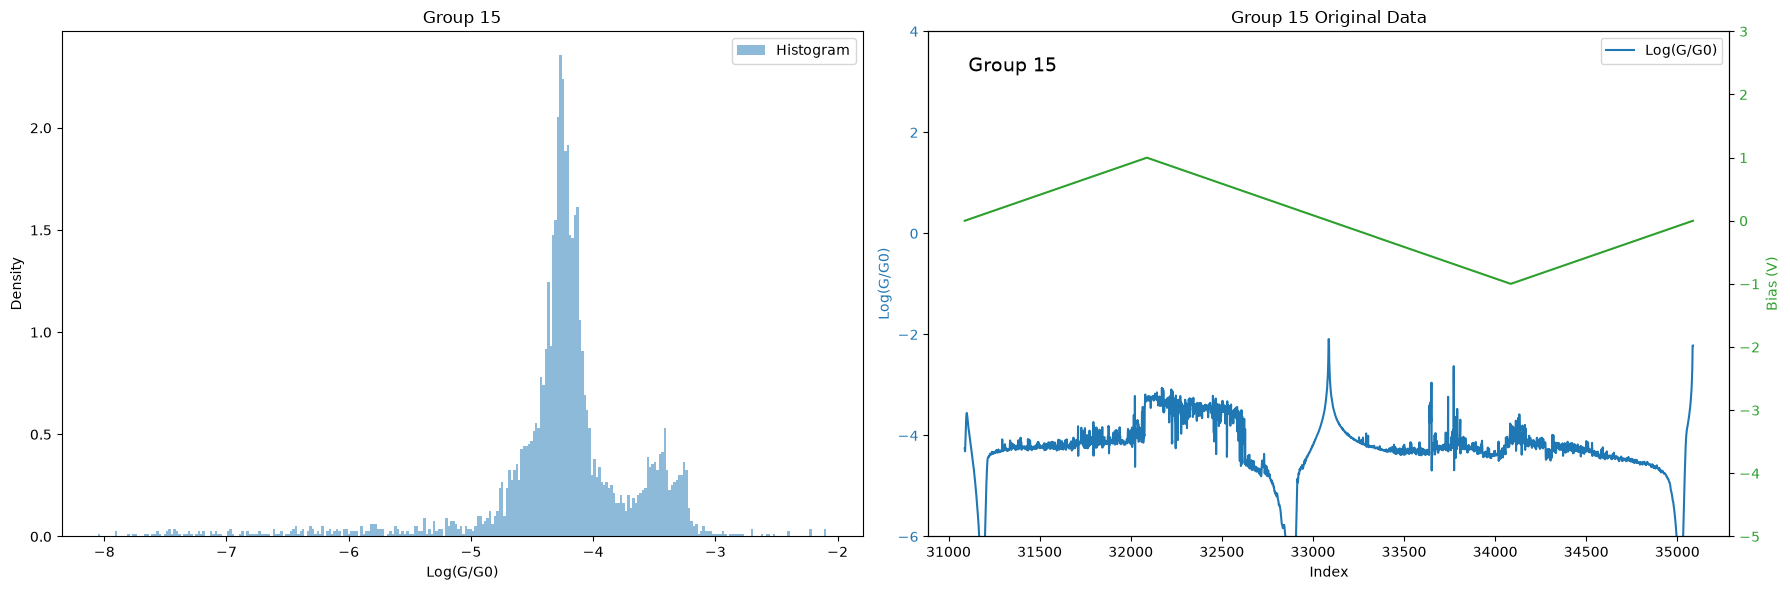

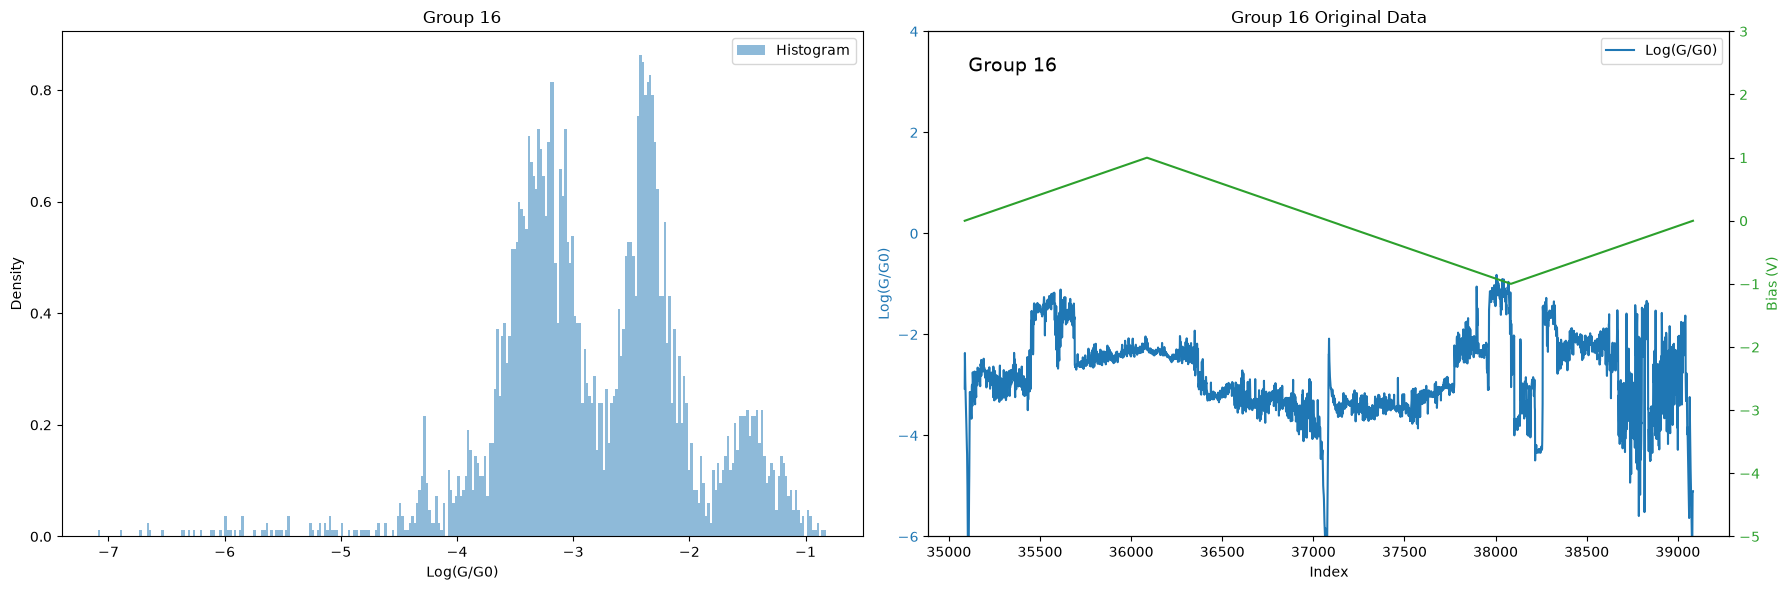

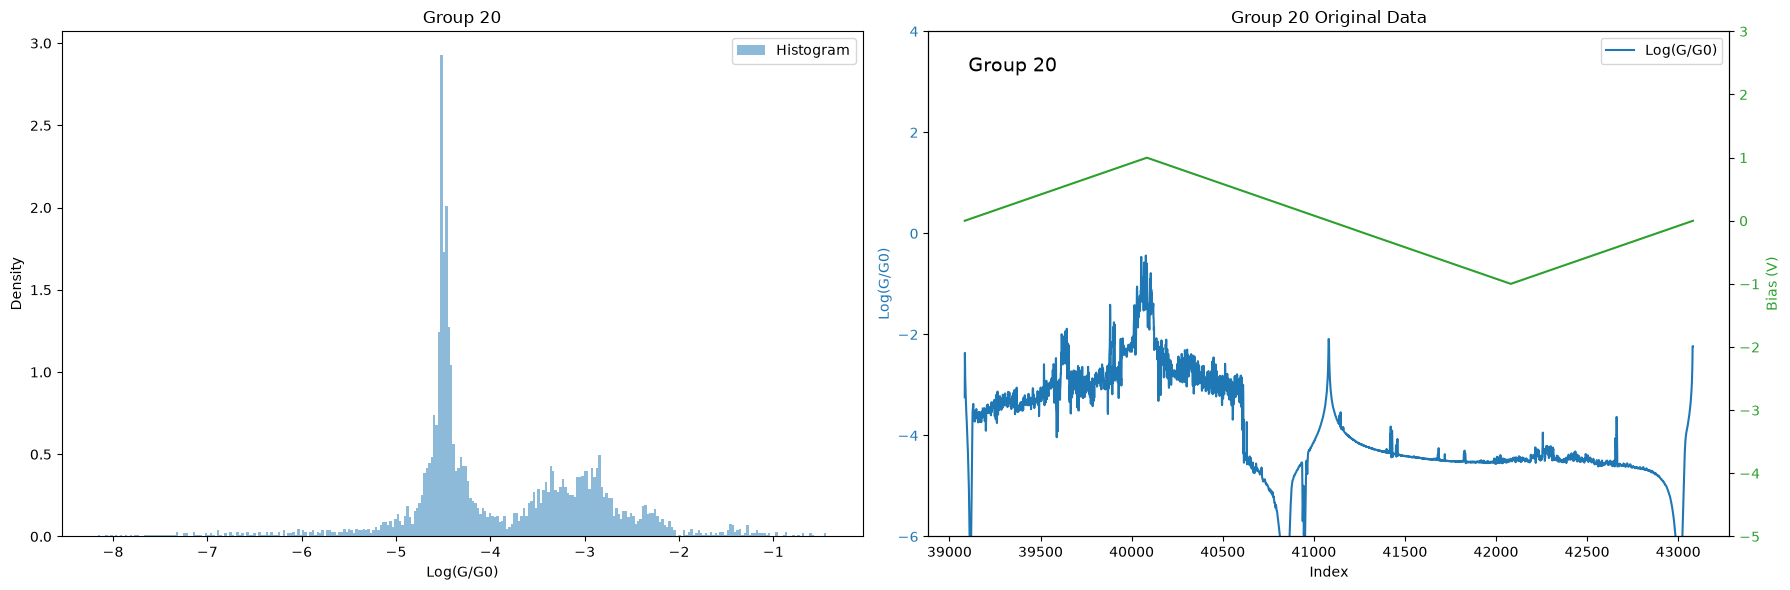

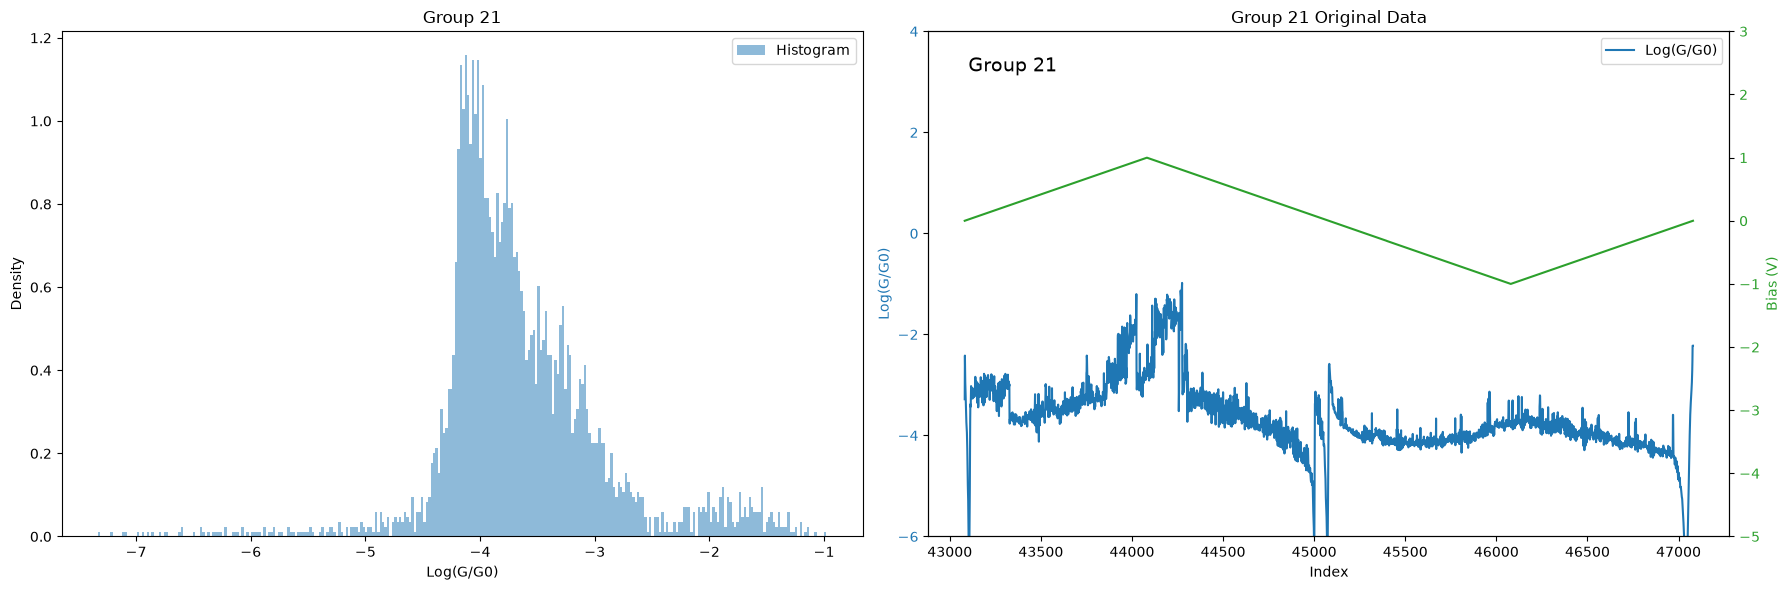

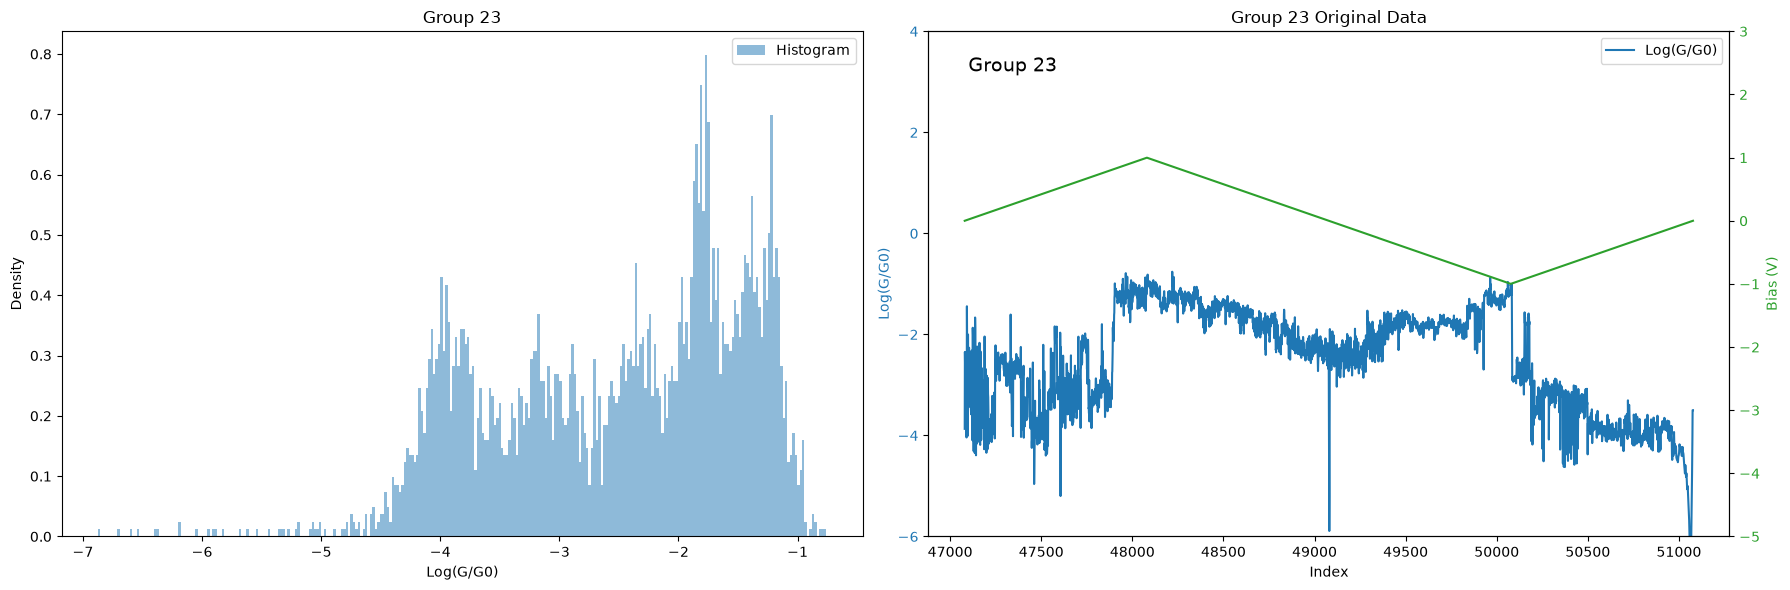

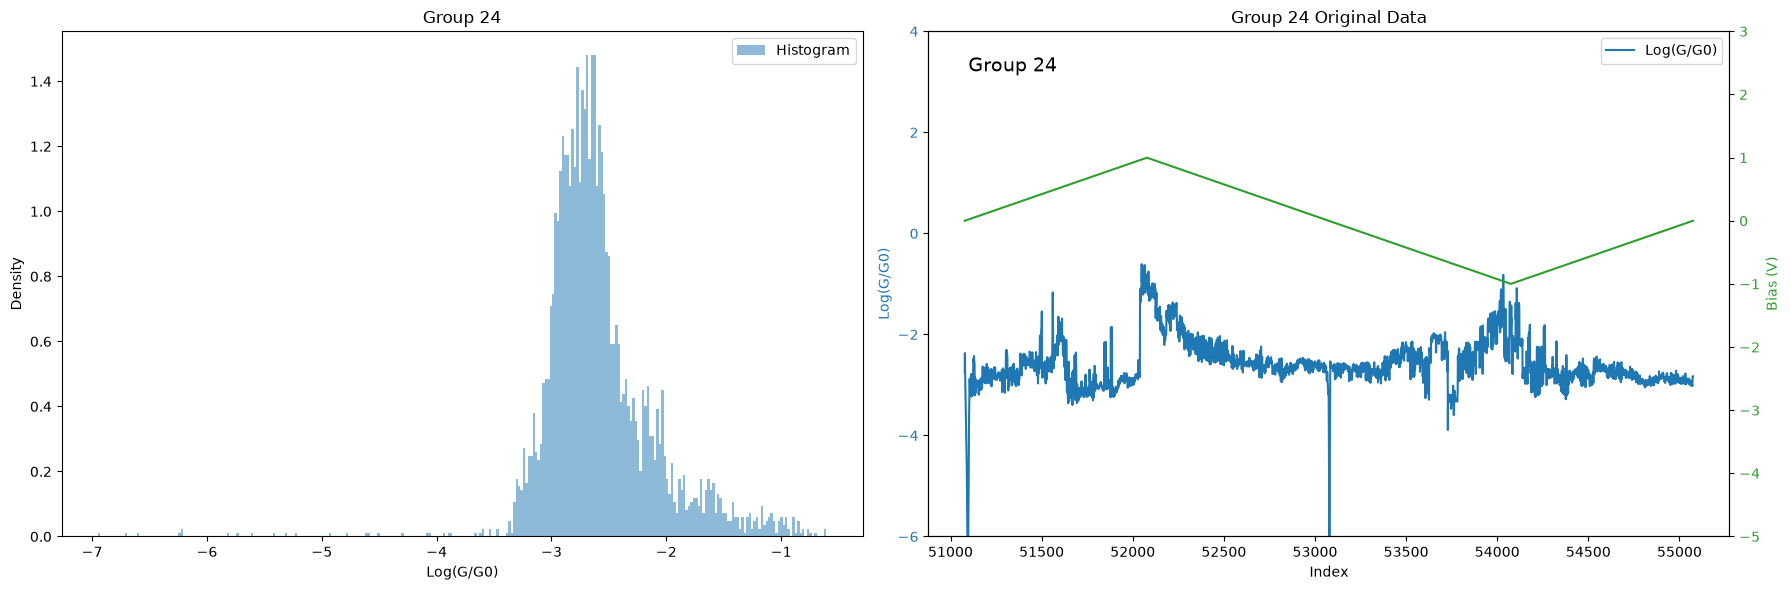

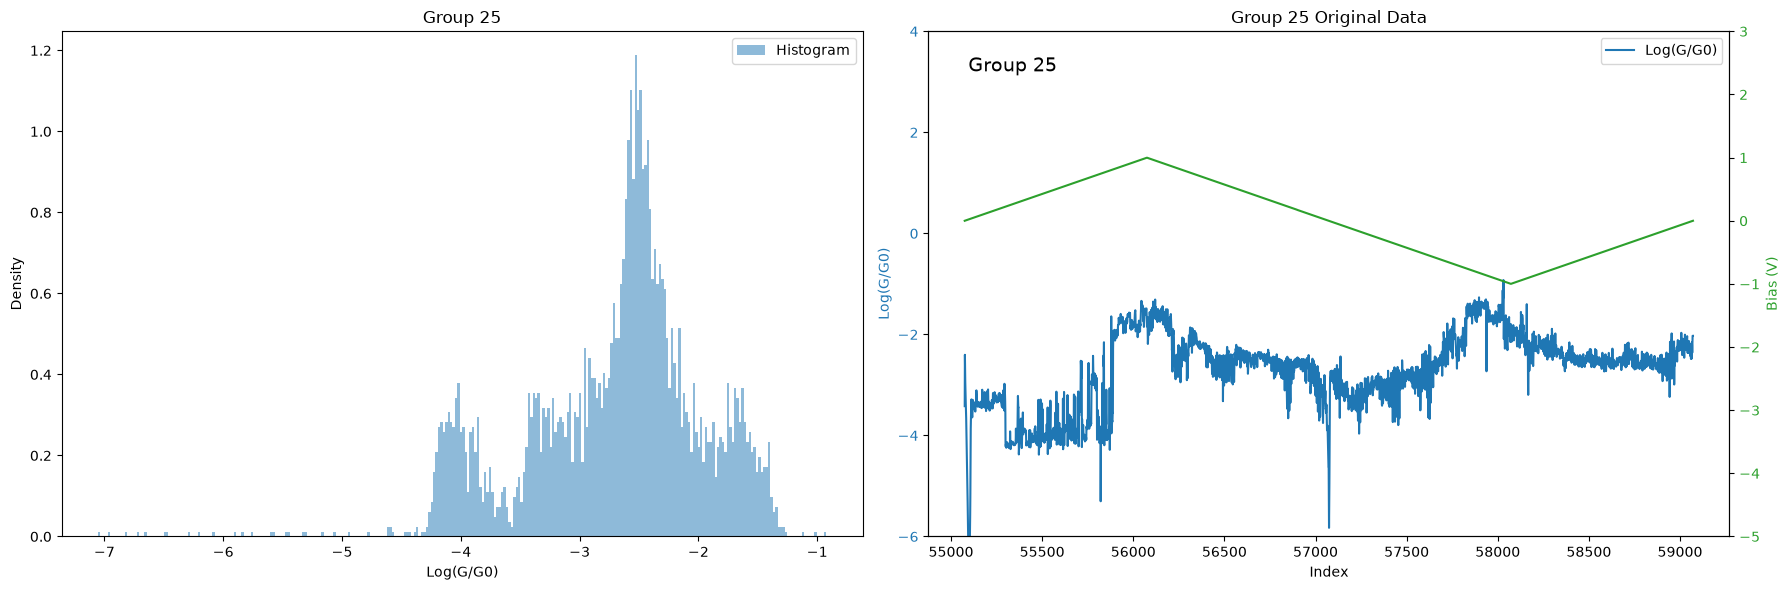

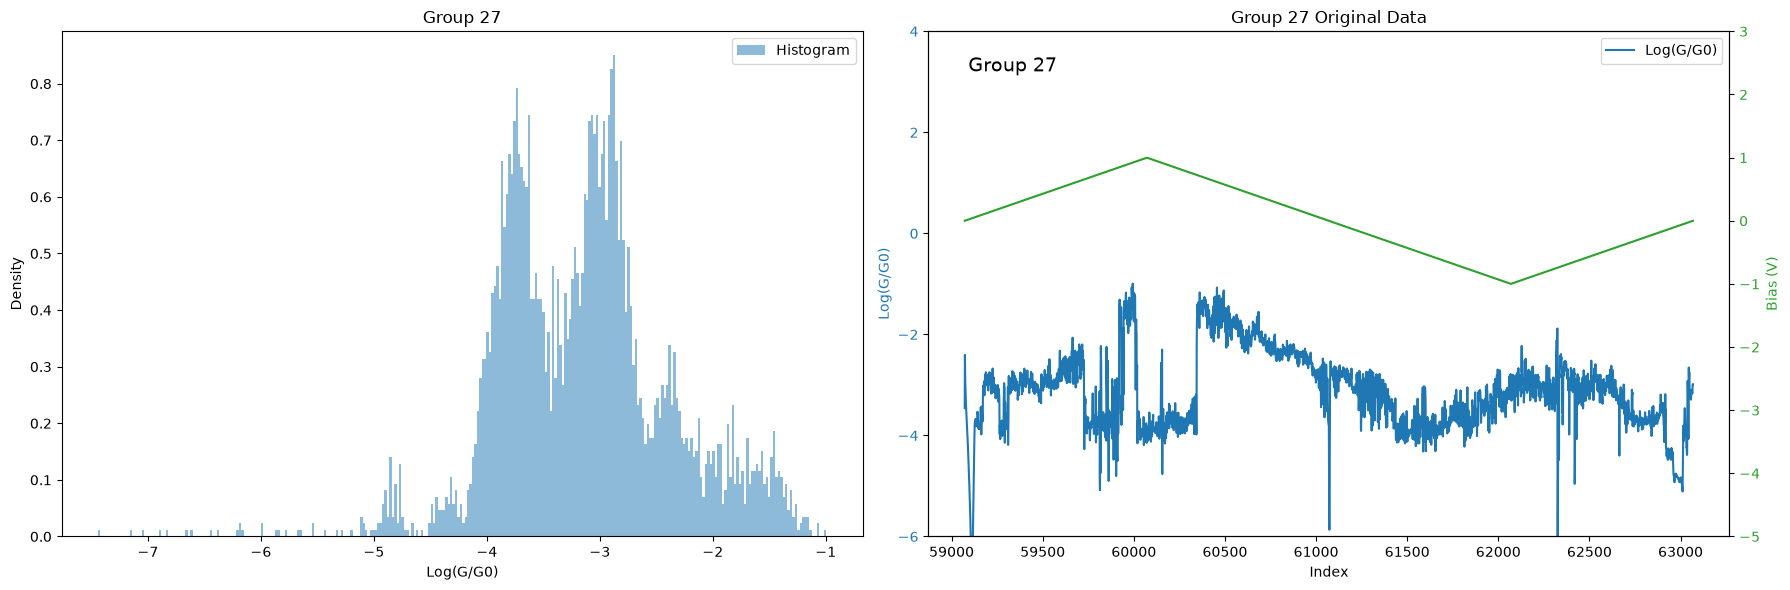

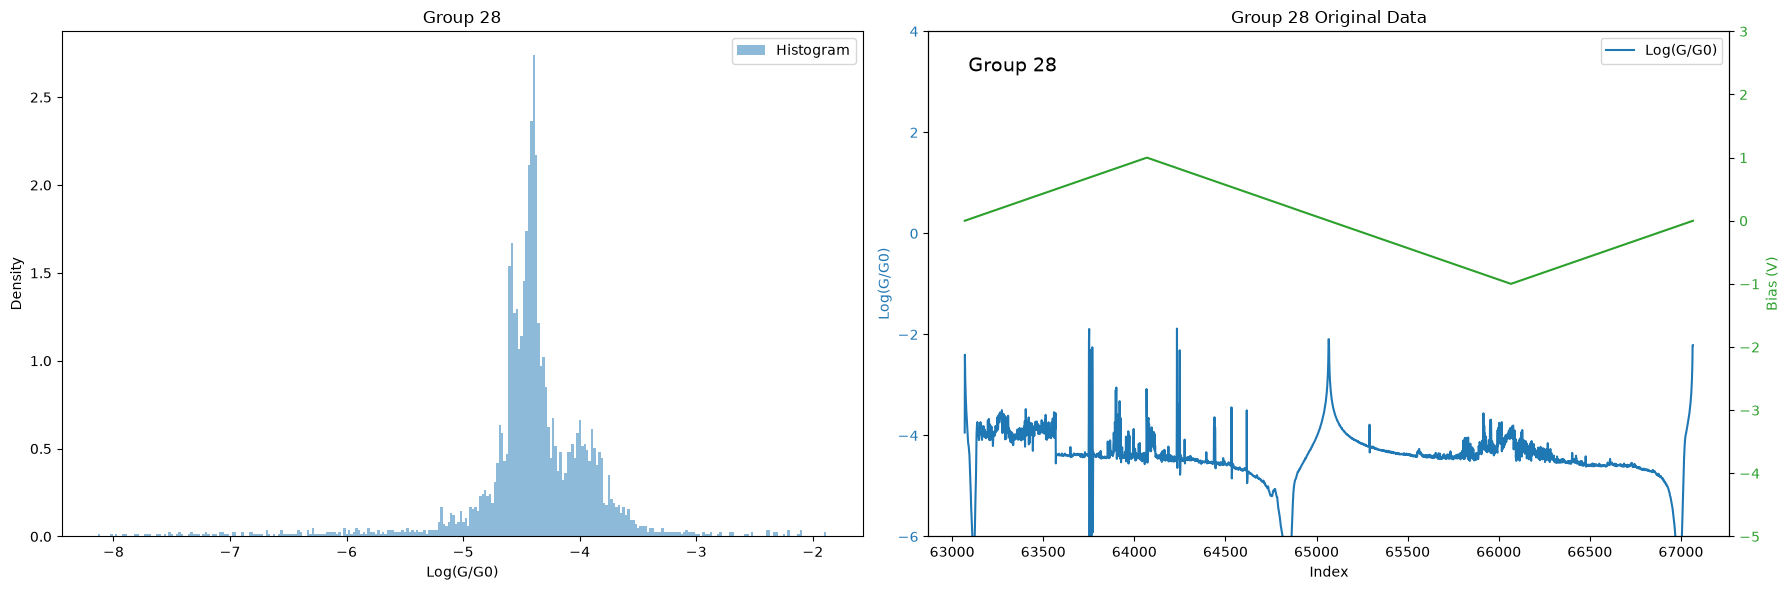

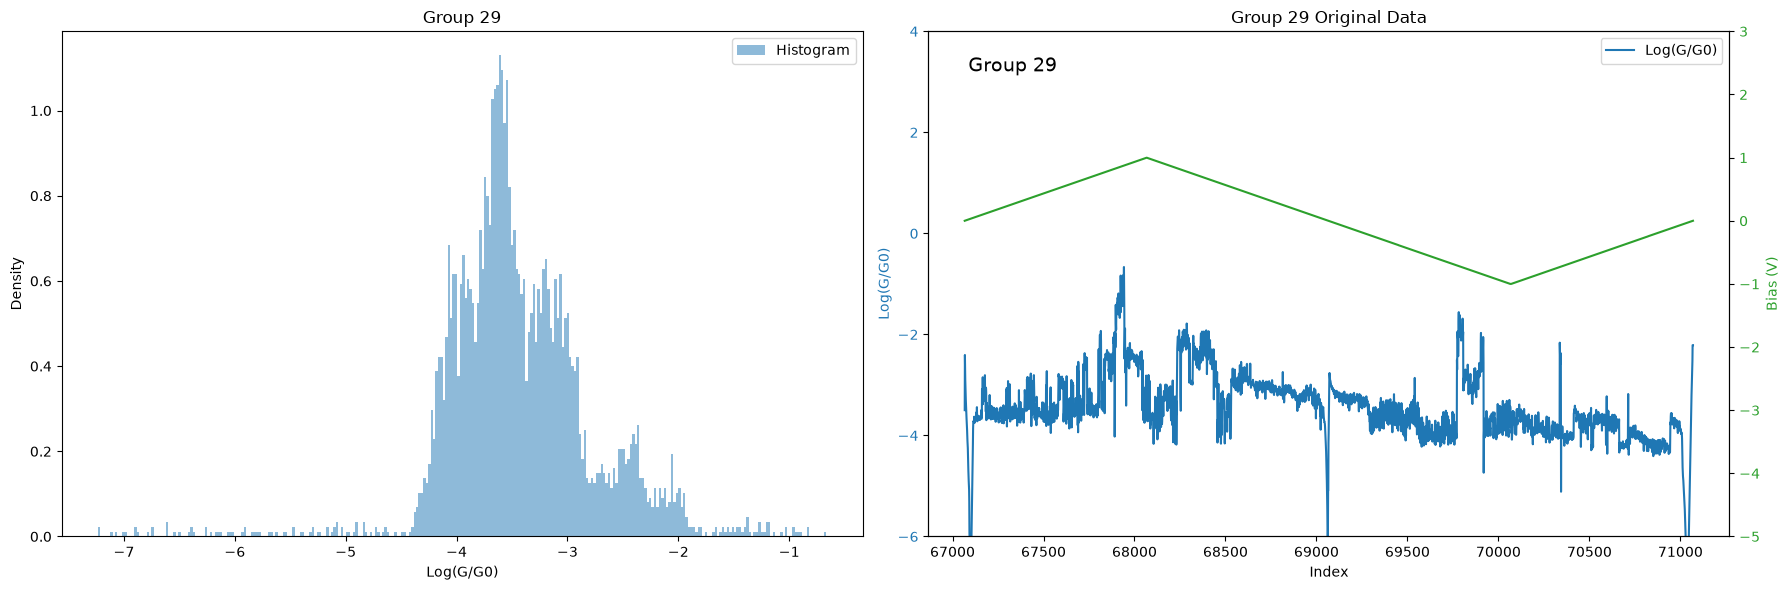

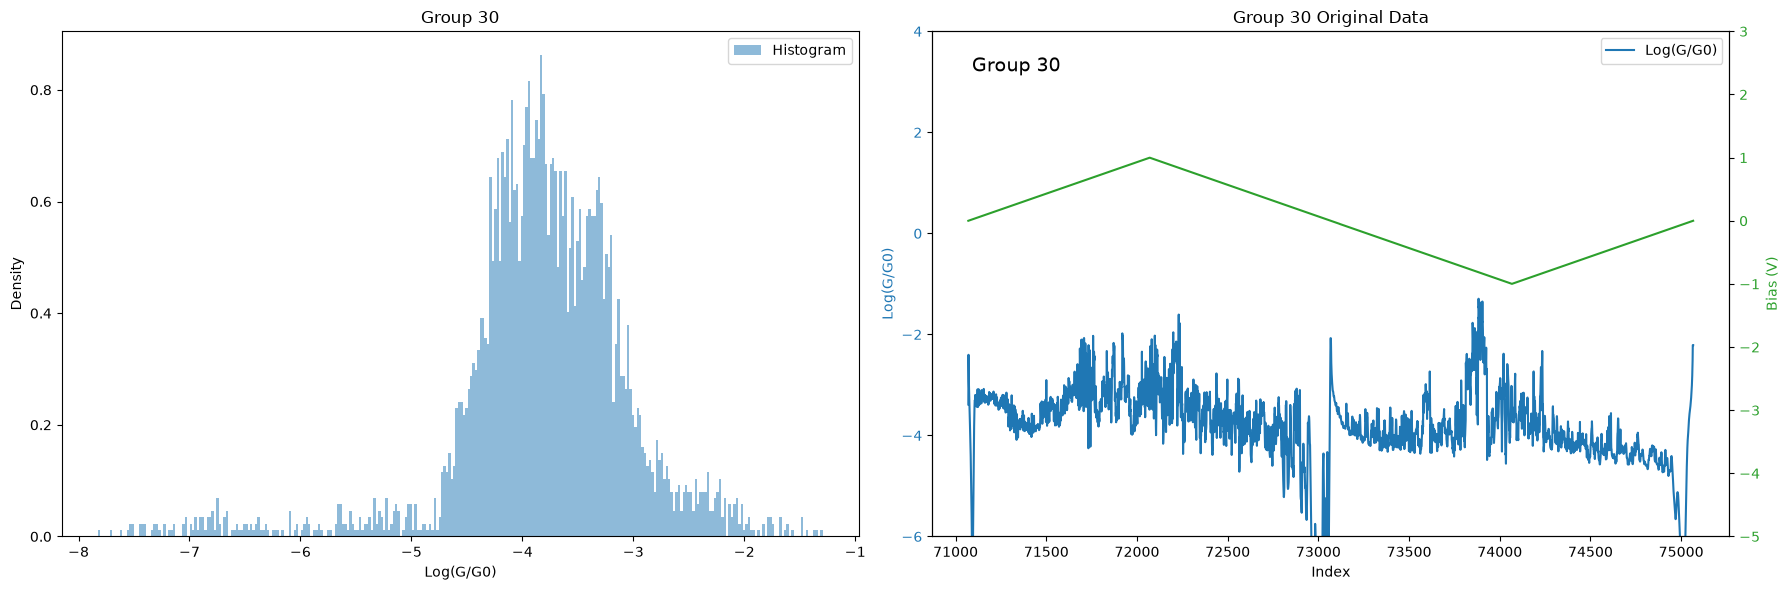

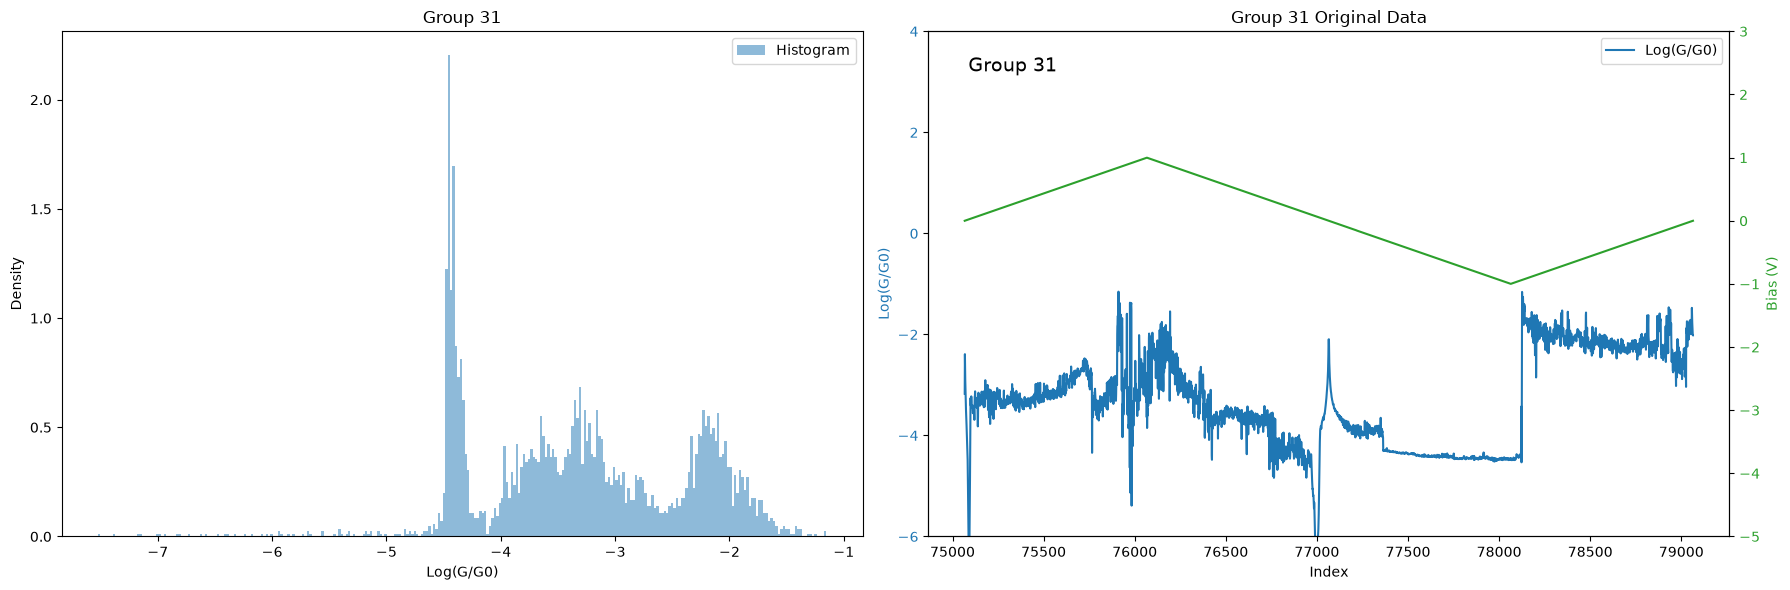

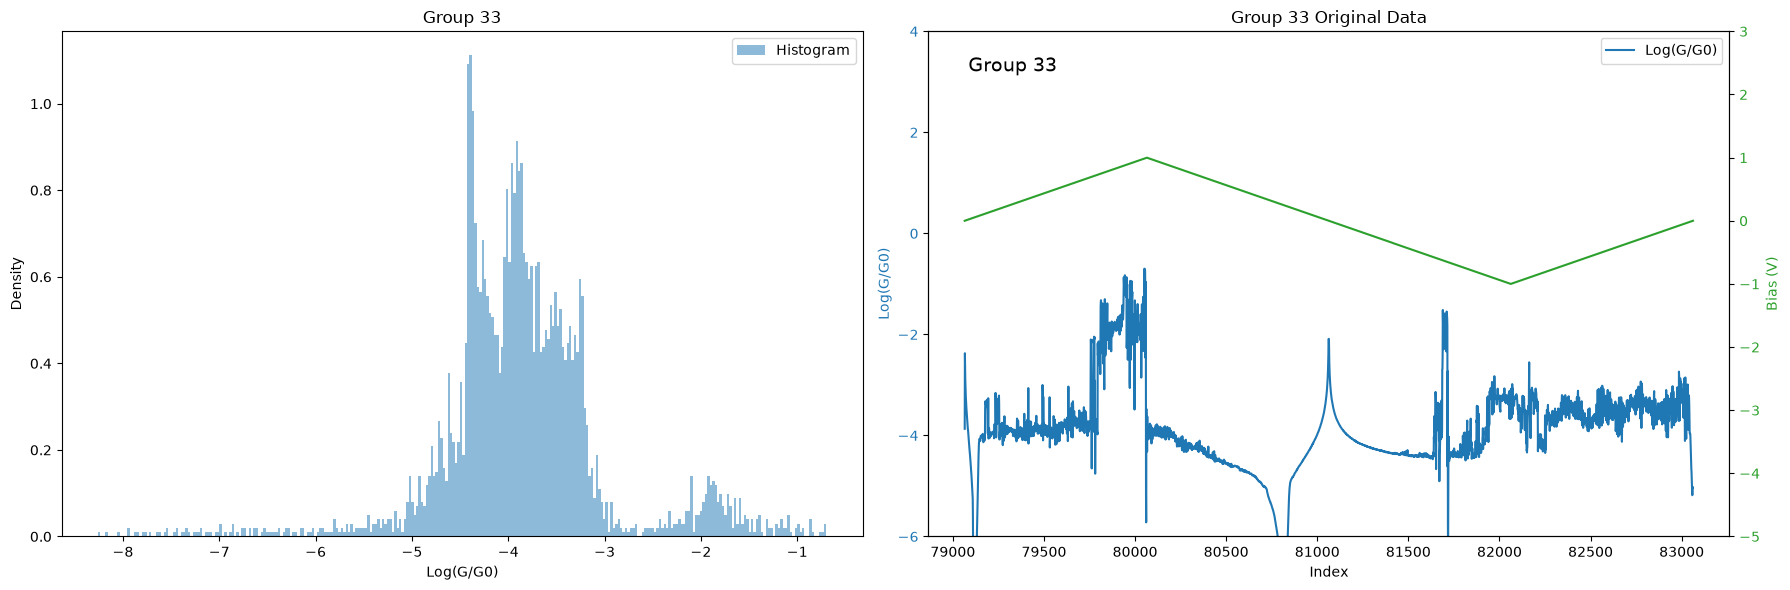

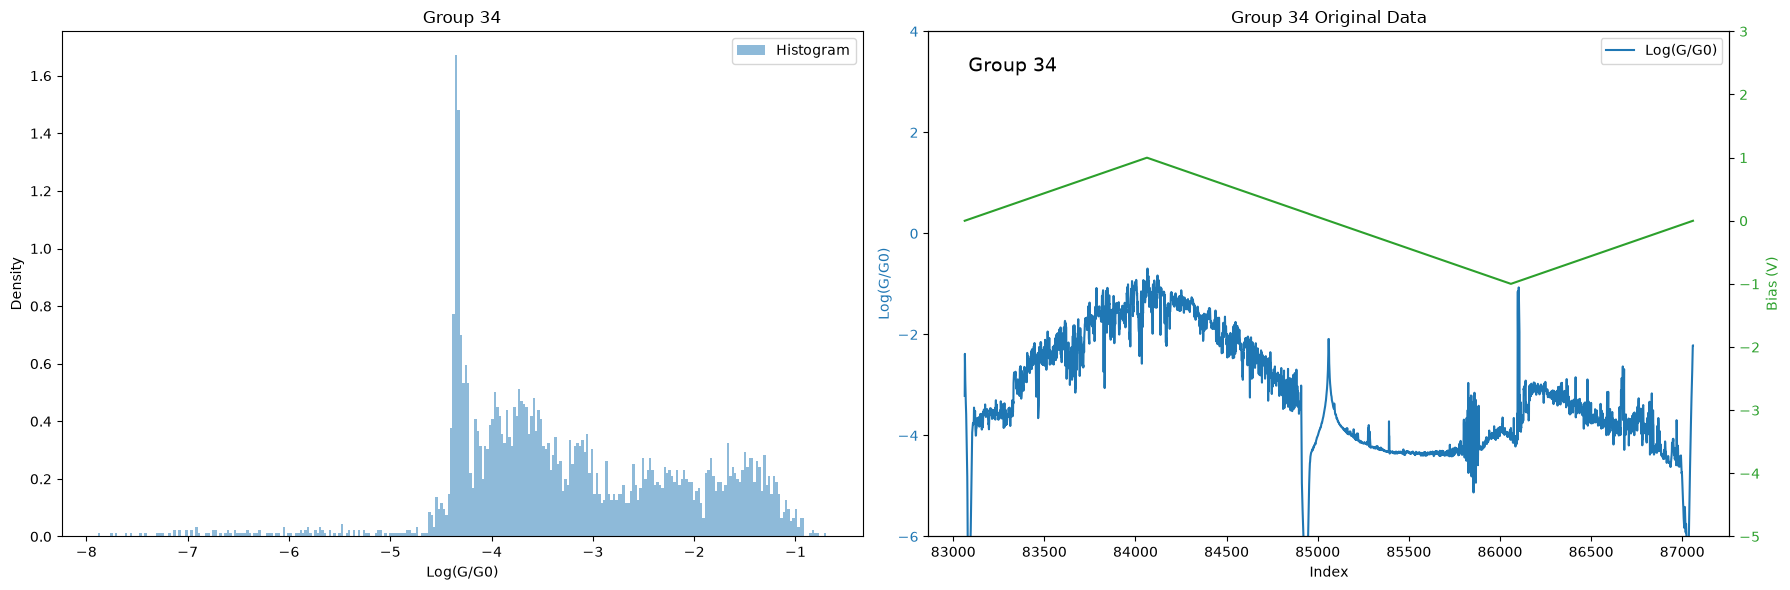

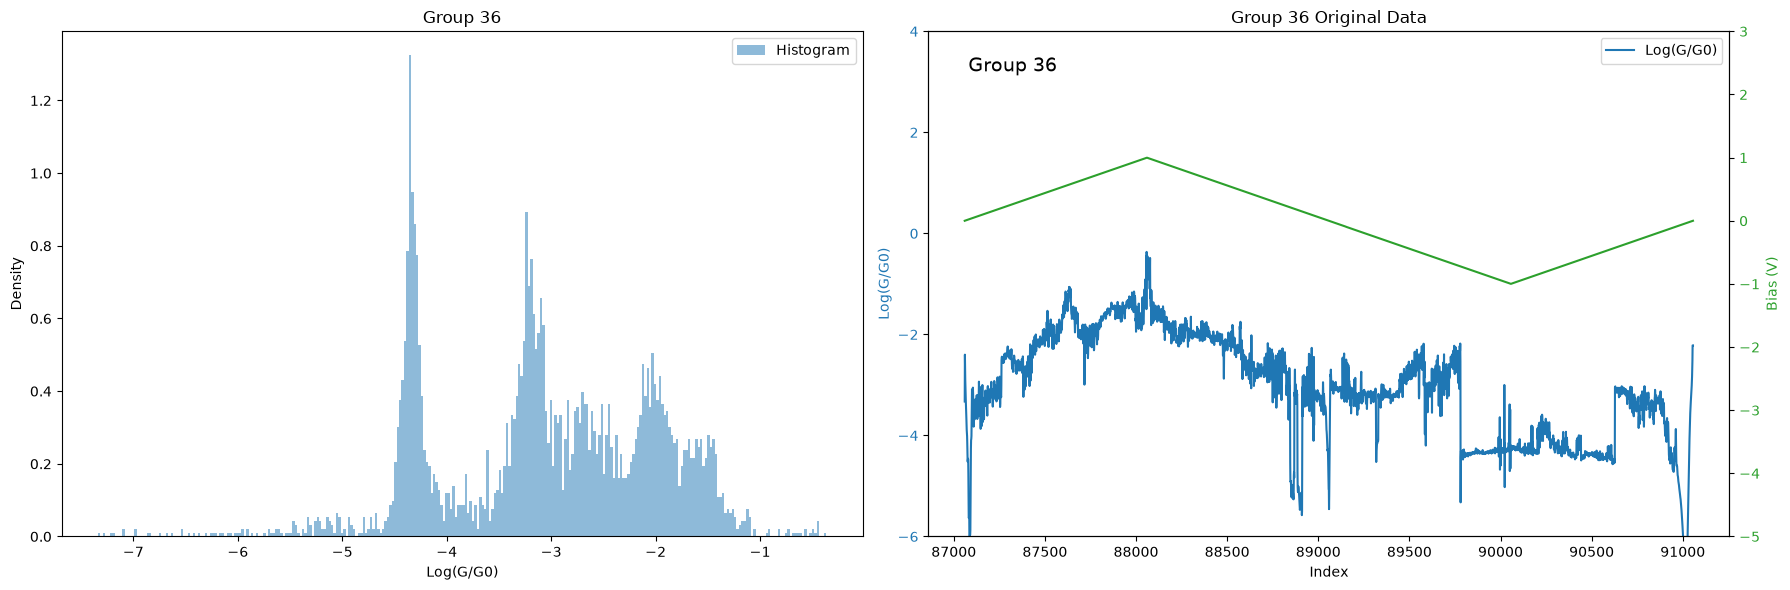

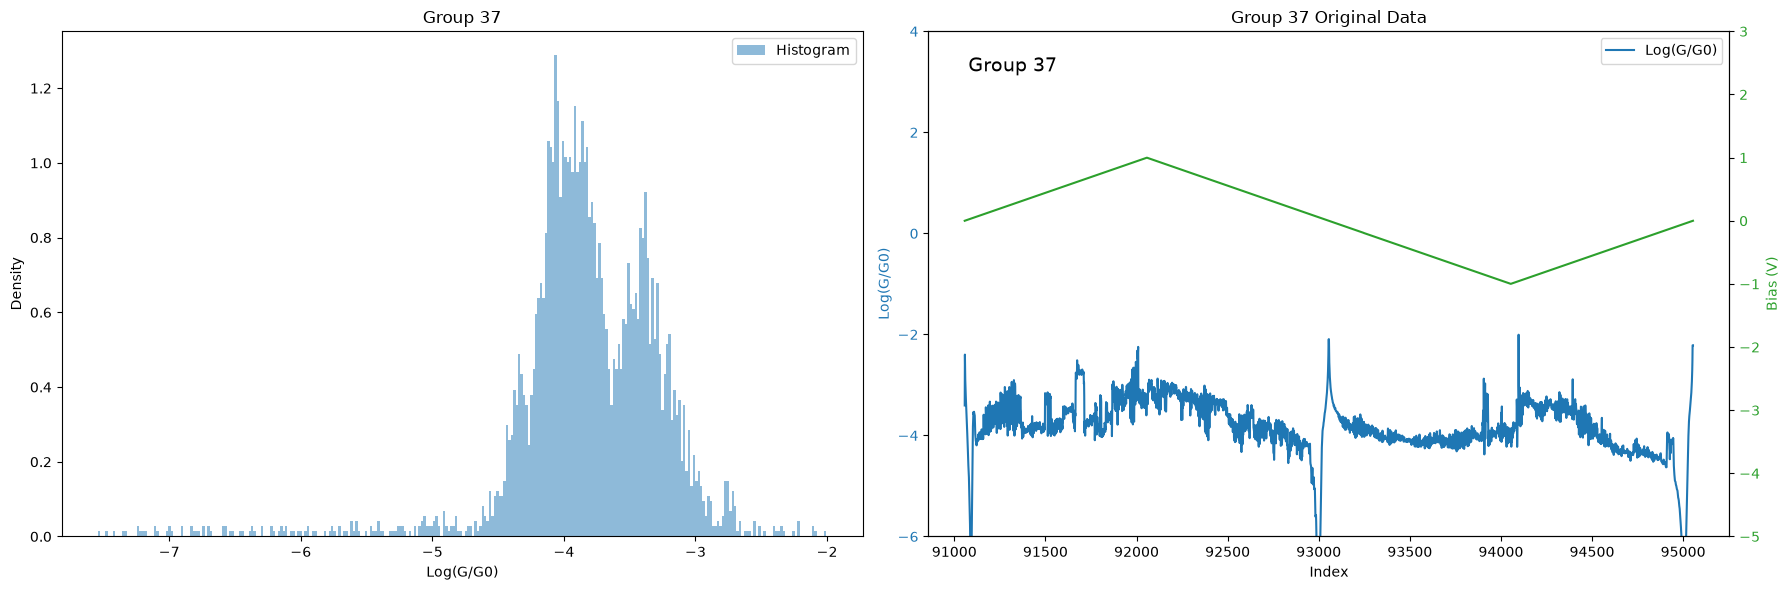

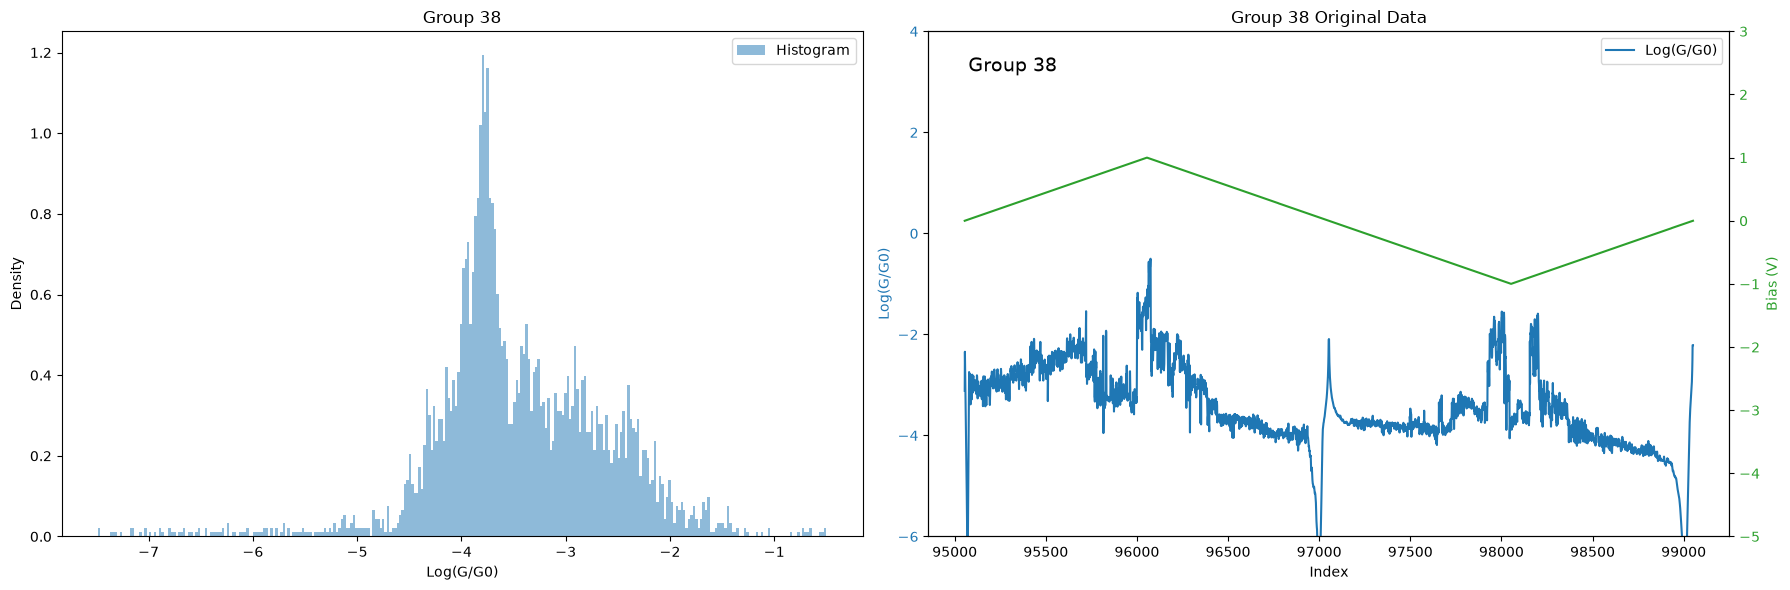

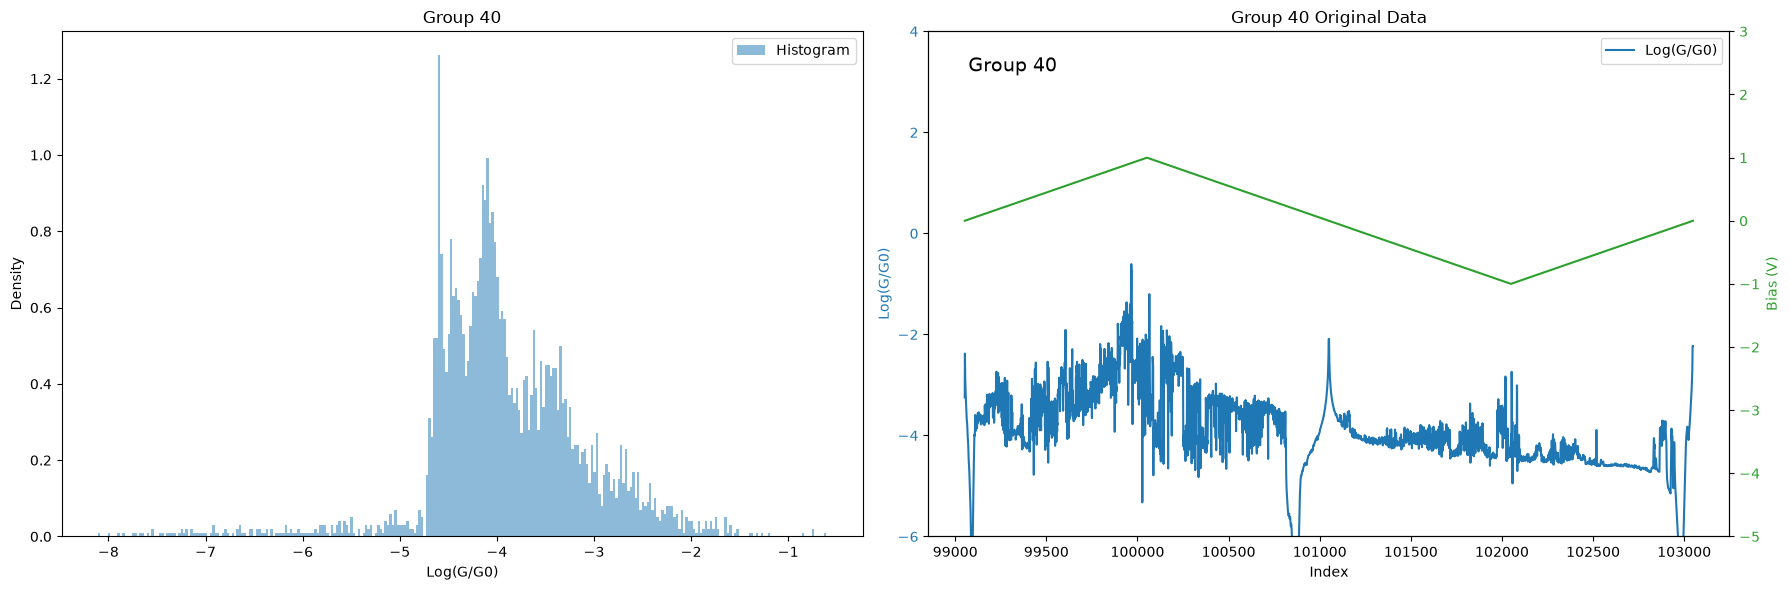

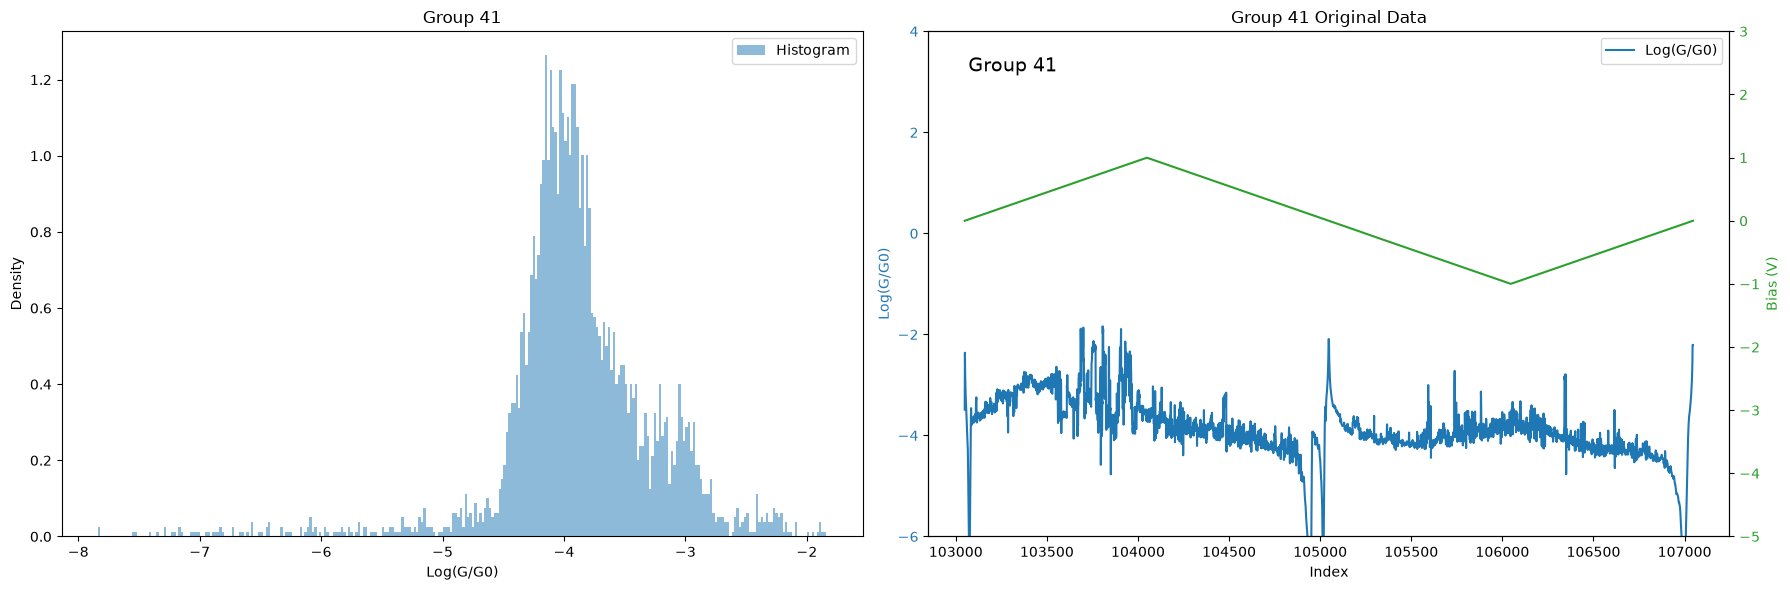

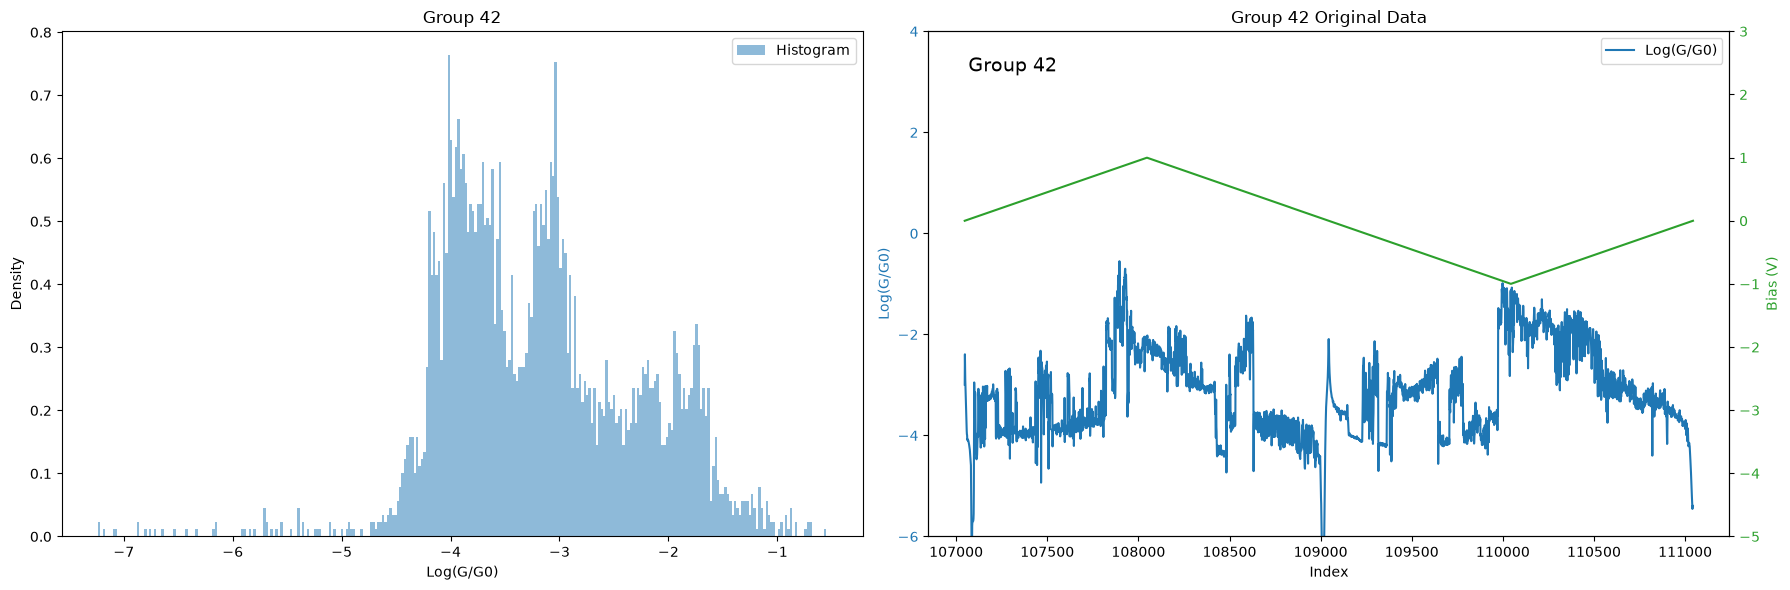

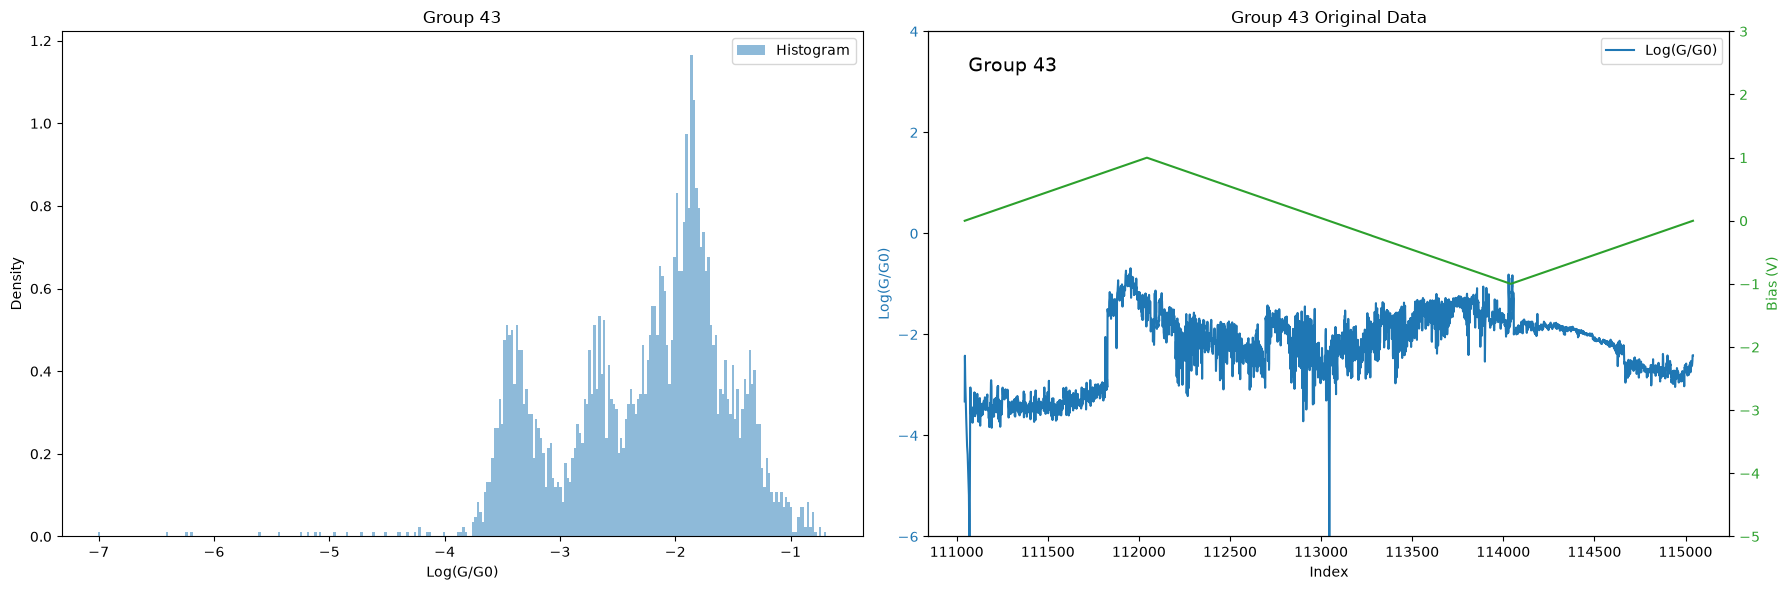

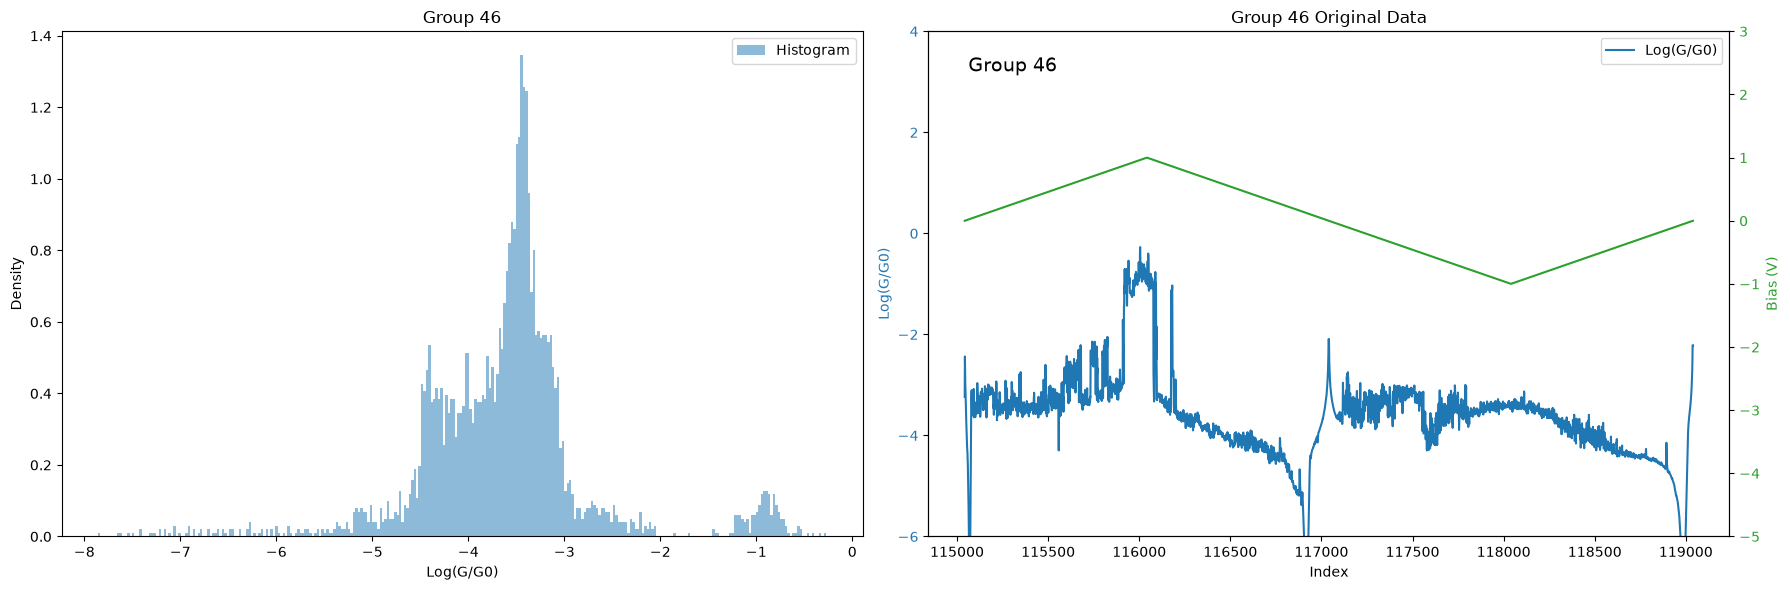

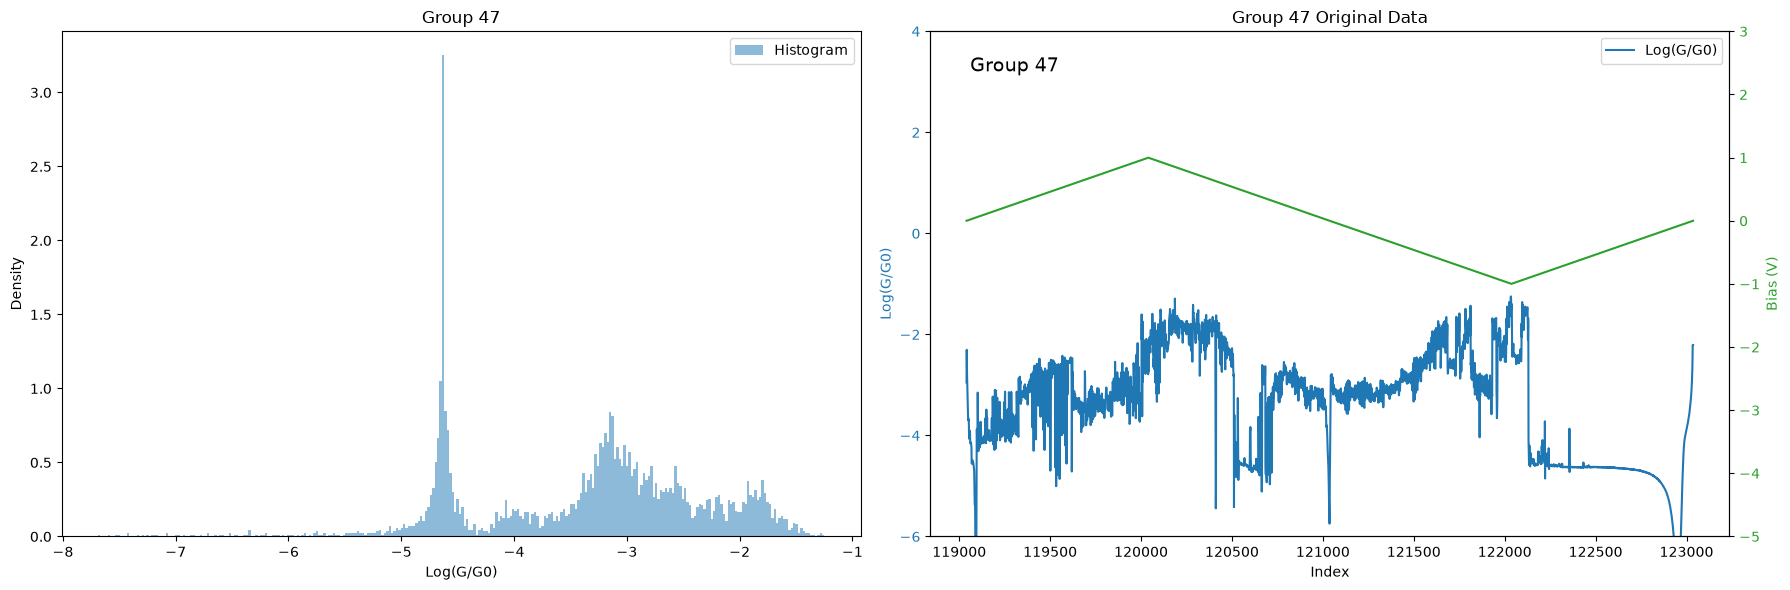

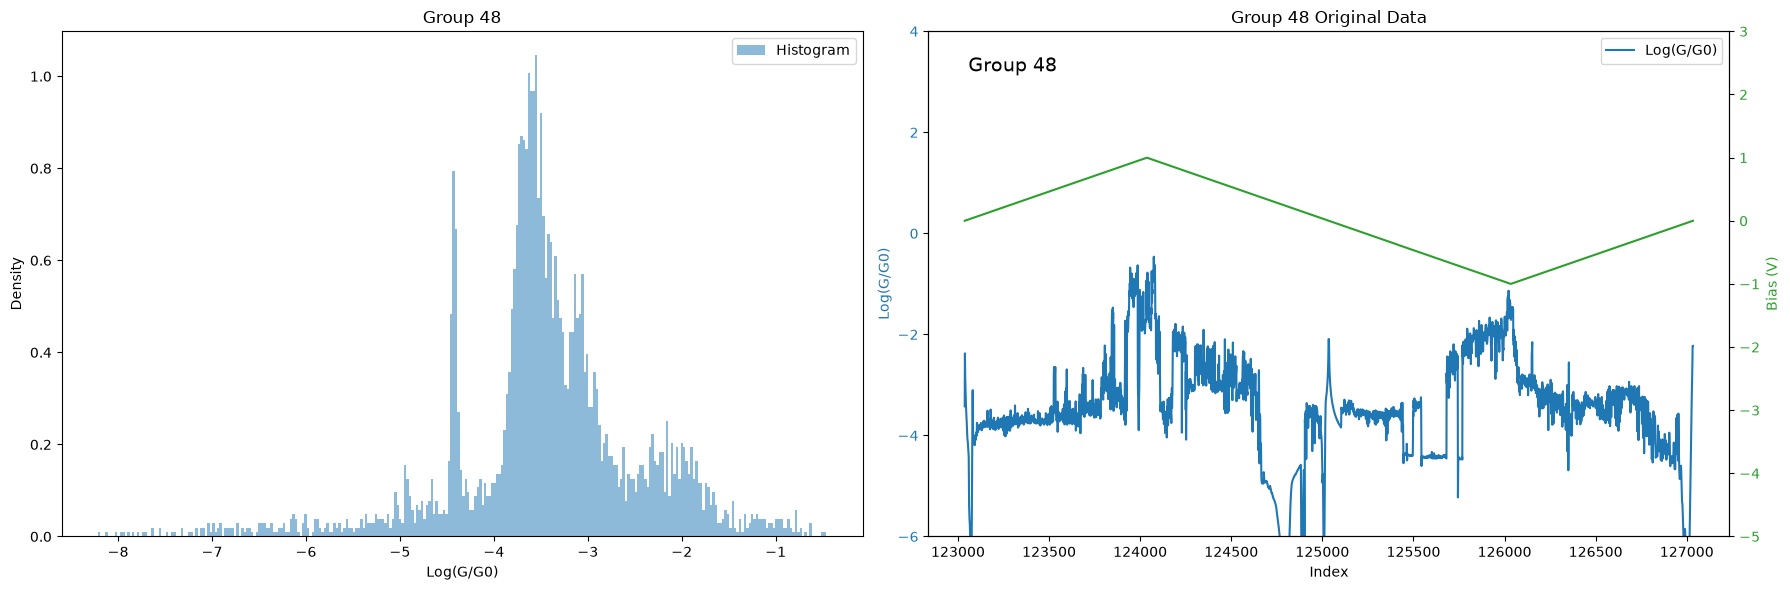

In [9]:
def drawdat(group_data, group_name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

    # 左侧：绘制直方图
    log_data = group_data['Log(G/G0)'].dropna()
    ax1.hist(log_data, bins=300, density=True, alpha=0.5, label='Histogram')
    ax1.set_xlabel('Log(G/G0)')
    ax1.set_ylabel('Density')
    ax1.legend()
    ax1.set_title(f'Group {group_name}')

    # 右侧：绘制原始单条曲线，包含两个Y轴
    ax3 = ax2.twinx()
    ax2.set_xlabel('Index')
    ax2.set_ylabel('Log(G/G0)', color='tab:blue')
    ax2.plot(group_data.index, group_data['Log(G/G0)'], color='tab:blue', label='Log(G/G0)')
    ax2.tick_params(axis='y', labelcolor='tab:blue')
    ax2.set_ylim(-6, 4)

    ax3.set_ylabel('Bias (V)', color='tab:green')
    ax3.plot(group_data.index, group_data['Bias (V)'], color='tab:green', label='Bias (V)')
    ax3.tick_params(axis='y', labelcolor='tab:green')
    ax3.set_ylim(-5, 3)

   

    # 添加 group_name 标签
    ax2.text(0.05, 0.95, f'Group {group_name}', transform=ax2.transAxes, fontsize=14, verticalalignment='top')

    ax2.set_title(f'Group {group_name} Original Data')
    ax2.legend()

    fig.tight_layout()
    plt.show()
for group_name, group_data in filtered_df.groupby('Number'):
        if group_name<50:
                drawdat(group_data, group_name)